# Options Market Making: A Desk Notebook
### Quoting a surface, getting picked off, hedging with costs, warehousing vega — and what the big firms actually get paid for

This notebook is written from the seat of an options market maker. The pricing-theory
notebook in this repo answers *"what is this option worth?"*; this one answers the questions a
market maker is actually paid to answer: *how wide do I quote and in what units, who is on the
other side and what do they know, how fast do I need to be before the underlying moves
through my quotes, how do I hedge when every hedge costs money, how does my inventory bend
the surface I'm quoting, and which of the trades the large firms are known for is really a
trade on what?*

Every piece of mathematics is implemented, **plotted**, and checked numerically against an
independent method before it is used downstream. The point of the visualisation is not
decoration: in market making the Greeks *are* the inventory, and a quote is a function of
them, so you need to see the shapes.

**Structure**

1. What an options market maker is paid for — the business model and the firms
2. The pricing engine and the Greeks — the objects every quote is built from (checked by finite differences)
3. Quoting in volatility, not price — vega as the exchange rate, and why the tick size decides who gets quoted
4. Adverse selection and the speed race — stale quotes, pick-off risk, and the optimal spread (Glosten-Milgrom, Budish-Cramton-Shim)
5. Delta hedging with real costs — the fundamental P&L identity, hedging error, Leland's volatility, and the Whalley-Wilmott no-trade band
6. The surface as the quoting engine — SVI fitting, no-arbitrage checks, sticky-strike vs. sticky-delta hedge ratios
7. Who is on the other side — sequential-trade learning and why retail flow is quoted tighter
8. The strategies the large firms are known for — dispersion, financing via boxes, earnings-event volatility, 0DTE and pin risk, the variance risk premium
9. Risk management — the spot/vol P&L grid, Greek ladders, and how inventory skews the quotes (Gârleanu-Pedersen-Poteshman)
10. Putting it together — a full options market-making simulation with toxic flow, inventory skew, hedge bands and a P&L explain
11. Method comparison and references

**Disclaimer.** Educational material on market-making theory, not investment advice, and not
production trading infrastructure. All "market" data is generated synthetically from models
built inside the notebook. Descriptions of what specific firms do are drawn from public
reporting (regulatory filings, exchange statistics, company statements) and describe
business lines, not proprietary models — nobody publishes those, and this notebook does not
pretend to.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cycler
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import norm, t as student_t
from scipy.optimize import brentq, least_squares
from scipy.integrate import quad
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

np.random.seed(42)
# One categorical palette, fixed order, used everywhere so a colour means the same thing on every chart.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams["axes.prop_cycle"] = cycler(color=PALETTE)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["font.size"] = 11

# The reference underlying for the whole notebook. Boring on purpose -- the interesting part is the book, not the stock.
S0  = 100.0    # spot
r   = 0.03     # risk-free rate, continuously compounded
q   = 0.01     # dividend yield
DAY = 1 / 252  # one trading day in years
print(f"S0={S0}, r={r}, q={q}, 1 day = {DAY:.5f} years")

S0=100.0, r=0.03, q=0.01, 1 day = 0.00397 years


## 1. What an options market maker is paid for

A market maker posts a bid and an ask on hundreds or thousands of option series simultaneously
and is obliged (as a Designated/Lead/Primary Market Maker, in exchange for fee rebates and
allocation priority) to keep those quotes live for most of the day. The business is not
"predict where the stock goes". It is, in order of importance:

1. **Capture the spread.** Buy on the bid, sell on the offer, as often as possible, with
   as little as possible of each fill being "informed". Section 3 shows the spread is set in
   *volatility* units and converted to price through vega; Sections 4 and 7 show what sets
   its width.
2. **Hedge what you can hedge.** Delta is hedged in the underlying within seconds; this
   converts "I sold a call" into "I am short gamma and vega with some theta coming in".
   Section 5 shows what that hedge costs and how often to do it.
3. **Warehouse what you cannot hedge, and get paid for it.** The residual Greeks — gamma,
   vega by expiry, skew, correlation — sit on the book until an offsetting customer shows
   up. The quotes must be skewed to attract that customer (Section 9) and the book must
   survive a vol spike while waiting (Sections 8e and 9).
4. **Be faster than the person trying to pick you off.** Every quote is a free option for
   anyone who sees the underlying move before you re-quote (Section 4). This is why the large
   firms run FPGA feed handlers and co-locate at every exchange: not to predict, but to cancel.

### The firms, and what is publicly known about their business lines

The options market-making industry is concentrated in a dozen or so firms. What follows is
drawn from public sources — SEC Rule 606 order-routing disclosures, exchange DMM/LMM
appointment lists, company statements and press coverage — and describes *lines of business*,
not internal models.

| Firm | Base | Public footprint relevant here | Sections |
|---|---|---|---|
| **Citadel Securities** | Chicago / Miami | Largest US wholesaler of retail equity *and* options order flow (per broker 606 reports); DMM on NYSE; major in index options | 3, 4, 7, 10 |
| **Susquehanna (SIG)** | Bala Cynwyd, PA | One of the largest options market makers globally since 1987; decision-theory ("edge over theo") trading culture; large index, ETF and single-stock options presence; wholesaling via its affiliated execution arm | 3, 7, 8a, 8b, 10 |
| **Optiver** | Amsterdam / Chicago | Grew out of Euronext index-options market making; large in index options (Euro Stoxx, SPX, 0DTE), ETFs and listed derivatives; heavy investment in low-latency hardware | 4, 6, 8d |
| **IMC** | Amsterdam / Chicago | Options and ETF market maker across US and Europe; DMM/LMM on multiple exchanges | 4, 6, 9 |
| **Jane Street** | New York | Best known for ETF arbitrage and for being a major liquidity provider in options and the financing trades (boxes, conversions) that link options to the funding market | 8b |
| **Wolverine Trading** | Chicago | Options market maker and one of the large options wholesalers | 7 |
| **Akuna Capital** | Chicago | Options market maker founded 2011 by Optiver alumni; large in US single-name and index options | 6, 9 |
| **DRW** | Chicago | Proprietary derivatives trading; fixed-income options, futures, crypto (Cumberland) | 8b |
| **Flow Traders** | Amsterdam | ETP liquidity provider; the options analogue of its business is Section 8a's basket-vs-components logic | 8a |
| **Bank flow desks** (Goldman, Morgan Stanley, JPMorgan, BofA) | New York / London | OTC and listed index-vol flow: dispersion, variance swaps, structured-product hedging — the natural counterparties to the firms above | 8a, 8e, 9 |

What they have in common is not a secret model. It is (i) a surface-based theo (Section 6),
(ii) spread and skew rules that are functions of the Greeks and the book (Sections 3, 9),
(iii) a toxicity model of the flow (Sections 4, 7), (iv) a disciplined hedging policy (Section
5), and (v) a risk framework built around the spot/vol grid (Section 9). The edge is in the
calibration, the speed, and the flow they see — not in the mathematics, which is what this
notebook can show you.

**Market structure facts the maths below leans on** (US listed options, as generally
described in exchange rulebooks and SEC commentary): 16-plus options exchanges; quotes
disseminated via OPRA at rates in the tens of billions of messages per day; a market maker's
quote on a series is typically re-sent every time the underlying's best bid/offer moves
("mass quoting"); price increments of \$0.01 below \$3 and \$0.05 above for penny-program
names, \$0.05/\$0.10 for most others; and the index-option complex (SPX, in particular) where
roughly half of recent volume has been in same-day-expiry (0DTE) contracts.

## 2. The pricing engine and the Greeks

**Source:** Black & Scholes (1973); Merton (1973) for the dividend yield. The Greeks are the
partial derivatives of the Black-Scholes price; vanna, volga and charm are the second-order
ones a market maker lives with (Taleb 1997, *Dynamic Hedging*, is the practitioner reference).

For a market maker the Black-Scholes model is not a belief about the world. It is a
*quoting convention*: the price is quoted as an implied volatility, and the Greeks of the
model are the coordinates in which inventory is measured. Even a desk whose "true" model is
stochastic-vol or local-vol reports its risk in these coordinates, because that is what the
hedging instruments (the underlying, and other options) move in.

With $d_1 = \frac{\ln(S/K) + (r - q + \sigma^2/2)T}{\sigma\sqrt T}$, $d_2 = d_1 - \sigma\sqrt T$:

$$
C = S e^{-qT} N(d_1) - K e^{-rT} N(d_2), \qquad
\Delta = e^{-qT}N(d_1), \quad
\Gamma = \frac{e^{-qT}\varphi(d_1)}{S\sigma\sqrt T}, \quad
\mathcal V = S e^{-qT}\varphi(d_1)\sqrt T
$$

$$
\text{Vanna} = \frac{\partial \Delta}{\partial \sigma} = -e^{-qT}\varphi(d_1)\frac{d_2}{\sigma}, \qquad
\text{Volga} = \frac{\partial \mathcal V}{\partial \sigma} = \mathcal V \frac{d_1 d_2}{\sigma}, \qquad
\text{Charm} = -\frac{\partial \Delta}{\partial T}
$$

Every closed form below is checked against central finite differences before anything else
is built on it.

In [2]:
def bs_d1_d2(S, K, T, r, q, sigma):
    sqT = np.sqrt(T)
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * sqT)
    return d1, d1 - sigma * sqT

def bs_price(S, K, T, r, q, sigma, kind="call"):
    d1, d2 = bs_d1_d2(S, K, T, r, q, sigma)
    if kind == "call":
        return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)

def bs_greeks(S, K, T, r, q, sigma, kind="call"):
    """Every Greek a desk reports, in one pass. Vega and theta are per unit (1.0 = 100 vol points, 1 year)."""
    d1, d2 = bs_d1_d2(S, K, T, r, q, sigma)
    sqT, eq, er, pdf = np.sqrt(T), np.exp(-q * T), np.exp(-r * T), norm.pdf(d1)
    sign = 1.0 if kind == "call" else -1.0
    delta = sign * eq * norm.cdf(sign * d1)
    gamma = eq * pdf / (S * sigma * sqT)
    vega  = S * eq * pdf * sqT
    theta = (-S * eq * pdf * sigma / (2 * sqT)
             - sign * r * K * er * norm.cdf(sign * d2)
             + sign * q * S * eq * norm.cdf(sign * d1))
    vanna = -eq * pdf * d2 / sigma
    volga = vega * d1 * d2 / sigma
    dd1_dT = (2 * (r - q) * T - d2 * sigma * sqT) / (2 * T * sigma * sqT)
    charm = sign * q * eq * norm.cdf(sign * d1) - eq * pdf * dd1_dT   # = -dDelta/dT, i.e. delta decay as the clock runs
    price = bs_price(S, K, T, r, q, sigma, kind)
    return dict(price=price, delta=delta, gamma=gamma, vega=vega, theta=theta,
                vanna=vanna, volga=volga, charm=charm)

def implied_vol(price, S, K, T, r, q, kind="call", lo=1e-4, hi=5.0):
    f = lambda s: bs_price(S, K, T, r, q, s, kind) - price
    return brentq(f, lo, hi, xtol=1e-10)

# --- finite-difference audit: if any of these fail, nothing downstream can be trusted ---
def fd_check(S, K, T, sigma, kind):
    g = bs_greeks(S, K, T, r, q, sigma, kind)
    hS, hs, hT = 1e-3, 1e-5, 1e-6
    P = lambda s_, sig_, T_: bs_price(s_, K, T_, r, q, sig_, kind)
    D = lambda s_, sig_, T_: bs_greeks(s_, K, T_, r, q, sig_, kind)["delta"]
    V = lambda s_, sig_, T_: bs_greeks(s_, K, T_, r, q, sig_, kind)["vega"]
    fd = dict(
        delta=(P(S + hS, sigma, T) - P(S - hS, sigma, T)) / (2 * hS),
        gamma=(P(S + hS, sigma, T) - 2 * P(S, sigma, T) + P(S - hS, sigma, T)) / hS**2,
        vega=(P(S, sigma + hs, T) - P(S, sigma - hs, T)) / (2 * hs),
        theta=-(P(S, sigma, T + hT) - P(S, sigma, T - hT)) / (2 * hT),
        vanna=(D(S, sigma + hs, T) - D(S, sigma - hs, T)) / (2 * hs),
        volga=(V(S, sigma + hs, T) - V(S, sigma - hs, T)) / (2 * hs),
        charm=-(D(S, sigma, T + hT) - D(S, sigma, T - hT)) / (2 * hT),
    )
    worst = 0.0
    for name, val in fd.items():
        rel = abs(g[name] - val) / (abs(val) + 1e-3)      # relative, with an absolute floor so a 4e-6 gamma isn't judged on its 7th digit
        worst = max(worst, rel)
        assert rel < 2e-4, f"{kind} {name}: closed form {g[name]:.8f} vs FD {val:.8f}"
    return worst

worst = max(fd_check(S, K, T, sig, kind)
            for S in (90.0, 100.0, 110.0) for K in (95.0, 105.0) for T in (0.05, 0.5)
            for sig in (0.15, 0.35) for kind in ("call", "put"))
print(f"All seven Greeks match central finite differences at 48 test points; worst relative error {worst:.2e}")

# Put-call parity -- the model-free identity every pricing engine must satisfy
c, p = bs_price(S0, 100.0, 0.5, r, q, 0.22, "call"), bs_price(S0, 100.0, 0.5, r, q, 0.22, "put")
assert abs((c - p) - (S0 * np.exp(-q * 0.5) - 100.0 * np.exp(-r * 0.5))) < 1e-10
print(f"Put-call parity holds: C-P = {c-p:.6f}")

All seven Greeks match central finite differences at 48 test points; worst relative error 3.19e-05
Put-call parity holds: C-P = 0.990054


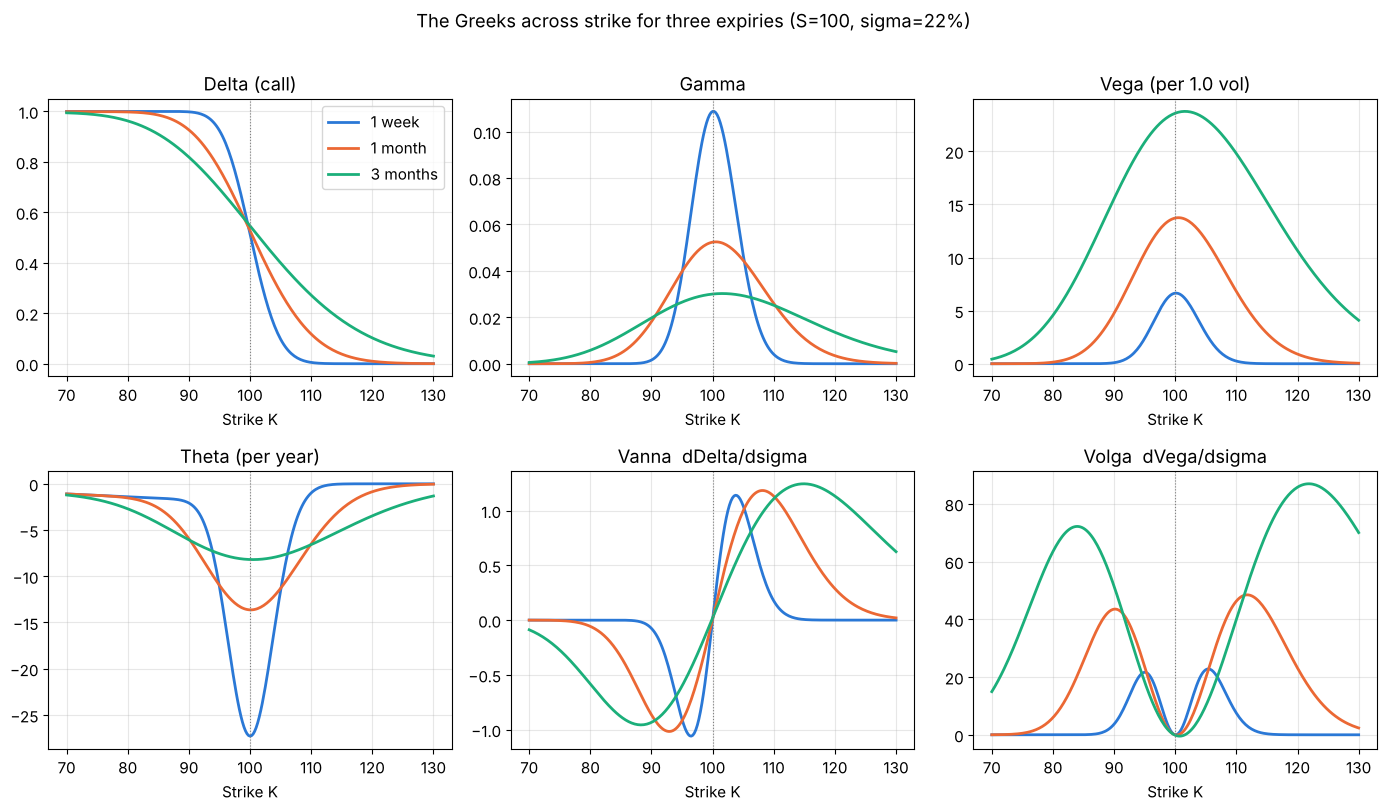

Read these as inventory maps: gamma and vanna concentrate near the money and short-dated,
vega lives in the long-dated options, volga sits in the wings. A book is a weighted sum of these.


In [3]:
# The shapes a market maker has memorised: how each Greek moves across strike and expiry.
strikes = np.linspace(70, 130, 241)
expiries = [(7 * DAY, "1 week"), (30 * DAY, "1 month"), (90 * DAY, "3 months")]
sigma_ref = 0.22

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
panels = [("delta", "Delta (call)"), ("gamma", "Gamma"), ("vega", "Vega (per 1.0 vol)"),
          ("theta", "Theta (per year)"), ("vanna", "Vanna  dDelta/dsigma"), ("volga", "Volga  dVega/dsigma")]
for ax, (key, title) in zip(axes.ravel(), panels):
    for T, label in expiries:
        g = bs_greeks(S0, strikes, T, r, q, sigma_ref, "call")
        ax.plot(strikes, g[key], lw=2, label=label)
    ax.axvline(S0, color="gray", lw=0.8, ls=":")
    ax.set_title(title); ax.set_xlabel("Strike K")
axes[0, 0].legend()
fig.suptitle("The Greeks across strike for three expiries (S=100, sigma=22%)", y=1.01)
plt.tight_layout(); plt.show()

print("Read these as inventory maps: gamma and vanna concentrate near the money and short-dated,")
print("vega lives in the long-dated options, volga sits in the wings. A book is a weighted sum of these.")

## 3. Quoting in volatility, not price

A desk does not quote 2,000 option prices; it quotes **one surface** in implied-volatility
units and lets the pricing engine turn it into prices. Two consequences follow from a single
first-order relation:

$$
\text{price half-spread} \;\approx\; \mathcal V \times \text{vol half-spread}
$$

1. **A constant spread in vol is a wildly non-constant spread in price.** ATM options have the
   most vega, so a 1-vol-point spread is widest in dollars at the money and collapses in the
   wings. This is what the quote screen actually looks like.
2. **The minimum price increment (the tick) is a floor on the vol spread, and it bites in the
   wings.** A far-OTM option with 0.2 cents of vega per vol point cannot be quoted tighter
   than 5 vol points wide, because the exchange will not accept a price between ticks. The
   market maker is *tick-constrained* there and the quote carries almost no information
   about the surface. Section 10 shows the consequence: uninformed flow in those strikes
   dries up because the spread is wide in the only units that matter to the customer.

**Edge.** Every fill is scored against the surface: $\text{edge} = (\text{theo} - \text{fill
price}) \times \text{side}$, or in vol, $\text{edge}_\sigma = \text{edge}/\mathcal V$. "Theo"
is the surface value. A desk's day is the sum of its edges minus what it gave back hedging
and warehousing them — that decomposition is Section 10.

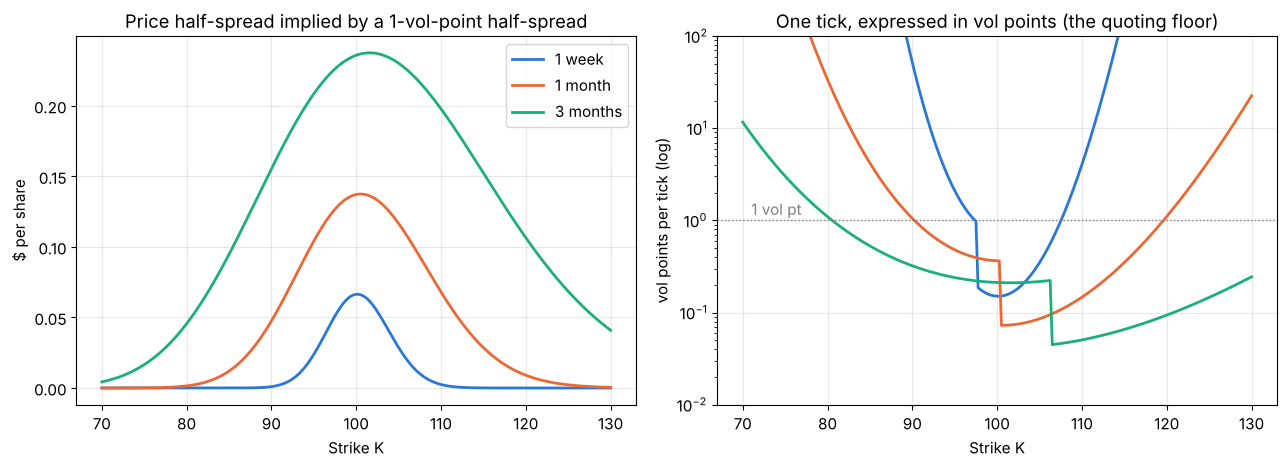

,Expiry,K,Call price,Vega per vol pt ($),One tick in vol pts
0,1 week,90,10.049,0.0010,51.44
1,1 week,95,5.178,0.0238,2.10
2,1 week,100,1.490,0.0664,0.15
3,1 week,105,0.165,0.0287,0.35
4,1 week,110,0.006,0.0025,4.05
5,1 month,90,10.454,0.0475,1.05
6,1 month,95,6.261,0.1042,0.48
7,1 month,100,3.141,0.1372,0.36
8,1 month,105,1.284,0.1166,0.09
9,1 month,110,0.424,0.0680,0.15


In [4]:
strikes = np.linspace(70, 130, 241)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for T, label in expiries:
    g = bs_greeks(S0, strikes, T, r, q, sigma_ref, "call")
    vega_per_point = g["vega"] * 0.01                     # dollars per 1 vol point, per share
    axes[0].plot(strikes, vega_per_point, lw=2, label=label)
    price = g["price"]
    tick = np.where(price < 3.0, 0.01, 0.05)              # penny-program increments
    axes[1].semilogy(strikes, tick / vega_per_point, lw=2, label=label)
axes[0].set_title("Price half-spread implied by a 1-vol-point half-spread")
axes[0].set_ylabel("$ per share"); axes[0].set_xlabel("Strike K"); axes[0].legend()
axes[1].set_title("One tick, expressed in vol points (the quoting floor)")
axes[1].set_ylabel("vol points per tick (log)"); axes[1].set_xlabel("Strike K")
axes[1].axhline(1.0, color="gray", ls=":", lw=1); axes[1].text(71, 1.15, "1 vol pt", color="gray")
axes[1].set_ylim(1e-2, 1e2)   # beyond 100 vol points per tick the option is unquotable anyway
plt.tight_layout(); plt.show()

rows = []
for T, label in expiries:
    for K in (90.0, 95.0, 100.0, 105.0, 110.0):
        g = bs_greeks(S0, K, T, r, q, sigma_ref, "call")
        vpp = float(g["vega"] * 0.01)
        tick = 0.01 if g["price"] < 3.0 else 0.05
        rows.append([label, int(K), f"{float(g['price']):.3f}", f"{vpp:.4f}", f"{tick / vpp:.2f}" if tick / vpp < 100 else ">100"])
pd.DataFrame(rows, columns=["Expiry", "K", "Call price", "Vega per vol pt ($)", "One tick in vol pts"])

## 4. Adverse selection and the speed race

**Sources:** Glosten & Milgrom (1985) for the idea that the spread is compensation for
trading against better-informed counterparties; Budish, Cramton & Shim (2015), *The
High-Frequency Trading Arms Race*, QJE, for the mechanics of *sniping* a stale quote; Copeland
& Galai (1983) for the observation that a standing limit order is a free option written to
the market.

An options quote is stale the instant the underlying moves. If the stock ticks up by $J$
before the market maker's new quotes reach the exchange, the old ask on a call with delta
$\Delta$ is now $\Delta J$ below fair value. Anyone faster than the market maker lifts it and
pockets $(\Delta|J| - h)^+$, where $h$ is the price half-spread. The market maker's
*expected loss per quote per unit time* is therefore

$$
\mathcal L(h, L) = \nu\; p_{\text{lose}}(L)\; \mathbb E\big[(\Delta |J| - h)^+\big]
$$

with $\nu$ the rate at which the underlying's mid moves, $p_{\text{lose}}(L)$ the probability
of losing the cancel-vs-take race at latency $L$, and $J$ the move size. Two models for $J$:

* **Diffusion.** $J \sim N(0, \sigma^2 S^2 L)$ — the textbook model. With $a = \Delta\sigma S\sqrt L$,
  $\;\mathbb E[(\Delta|J| - h)^+] = 2\left[a\,\varphi(h/a) - h\,(1 - \Phi(h/a))\right]$. This
  says sub-second latency costs essentially nothing, because a diffusive move over 100 ms is
  a fraction of a tick.
* **Jumps.** The underlying's mid moves in discrete ticks, mostly one at a time but with a fat
  tail (news, a sweep through several levels). This is what actually gets market makers
  picked off, and it is why the race is measured in microseconds: the loss is proportional to
  $p_{\text{lose}}(L)$, and that is the only term the firm controls.

The optimal half-spread then trades sniping losses against the elasticity of uninformed
demand, $\lambda(h) = A e^{-k h}$ (the same arrival model as Avellaneda-Stoikov):

$$
h^\star = \arg\max_h \; \underbrace{A e^{-kh}\, h}_{\text{spread revenue}} \;-\; \underbrace{\nu\, p_{\text{lose}}(L)\, \mathbb E[(\Delta|J|-h)^+]}_{\text{sniping cost}}
$$

In [5]:
def pickoff_loss_diffusion(delta, sigma_S, L_seconds, h, S=S0):
    """Closed form E[(Delta*|J| - h)^+] for J ~ N(0, sigma^2 S^2 L), i.e. a half-normal with scale a."""
    secs_per_year = 252 * 6.5 * 3600
    a = np.abs(delta) * sigma_S * S * np.sqrt(L_seconds / secs_per_year)
    return 2 * (a * norm.pdf(h / a) - h * (1 - norm.cdf(h / a)))

# --- check the closed form against brute force with FULL Black-Scholes repricing (gamma included) ---
rng = np.random.default_rng(4)
T_chk, sigma_chk, L_chk, h_chk = 30 * DAY, 0.40, 5.0, 0.025      # 40% intraday vol, 5 s stale, 2.5c half-spread
g_chk = bs_greeks(S0, 100.0, T_chk, r, q, sigma_chk, "call")
secs_per_year = 252 * 6.5 * 3600
dS = sigma_chk * S0 * np.sqrt(L_chk / secs_per_year) * rng.standard_normal(400_000)
new_fair = bs_price(S0 + dS, 100.0, T_chk, r, q, sigma_chk, "call")
gain = np.maximum(np.abs(new_fair - g_chk["price"]) - h_chk, 0.0)   # sniper lifts the ask on an up-move, hits the bid on a down-move
mc, se = gain.mean(), gain.std() / np.sqrt(len(gain))
cf = pickoff_loss_diffusion(g_chk["delta"], sigma_chk, L_chk, h_chk)
print(f"E[(Delta|J|-h)^+]  closed form (delta only): {cf:.6f}   MC with full repricing: {mc:.6f} +/- {1.96*se:.6f}")
assert abs(mc - cf) < 0.05 * cf + 3 * se, "half-normal pick-off formula disagrees with simulation"
print("Gamma adds a small second-order amount on top of the delta-only closed form, as it should (|dS| is tiny here).")

E[(Delta|J|-h)^+]  closed form (delta only): 0.001901   MC with full repricing: 0.001900 +/- 0.000016
Gamma adds a small second-order amount on top of the delta-only closed form, as it should (|dS| is tiny here).


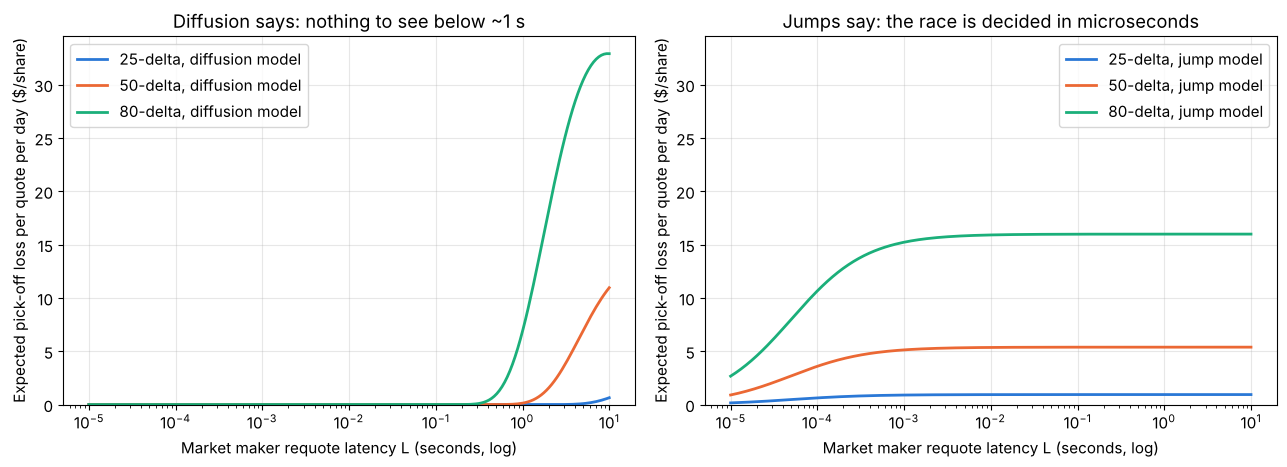

At   1000 us requote latency a 50-delta quote leaks 5.126 $/share/day; quoting one contract on each of 500 such series costs ~$256,286/day before any spread is earned.
At    100 us requote latency a 50-delta quote leaks 3.588 $/share/day; quoting one contract on each of 500 such series costs ~$179,400/day before any spread is earned.
At     20 us requote latency a 50-delta quote leaks 1.538 $/share/day; quoting one contract on each of 500 such series costs ~$76,886/day before any spread is earned.
Same flow, same spreads: the difference between the rows is purely who wins the cancel race. That is the arms race in one table.


In [6]:
# A jump model for the underlying's mid: mostly one tick, sometimes a sweep. Rate nu per second.
tick_S = 0.01
jump_ticks = np.array([1, 2, 3, 5, 10, 20, 50])
jump_prob  = np.array([0.8490, 0.1000, 0.0300, 0.0150, 0.0050, 0.0008, 0.0002])   # ~140 ten-cent-plus jumps a day, ~5 fifty-cent ones
assert abs(jump_prob.sum() - 1) < 1e-12
nu = 1.0          # mid changes per second in a liquid name during the day

def pickoff_loss_jumps(delta, h):
    return np.sum(jump_prob * np.maximum(np.abs(delta) * jump_ticks * tick_S - h, 0.0))

def p_lose_race(L_mm, L_sniper=50e-6):
    """Probability the market maker's cancel loses to the fastest taker. A simple
    'who gets there first with exponential jitter' model: L/(L+L_sniper)."""
    return L_mm / (L_mm + L_sniper)

latencies = np.logspace(-5, 1, 200)       # 10 microseconds to 10 seconds
h_ref = 0.025
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for delta, lab in [(0.25, "25-delta"), (0.50, "50-delta"), (0.80, "80-delta")]:
    diff_loss = np.array([pickoff_loss_diffusion(delta, 0.40, L, h_ref) for L in latencies]) / latencies   # per second: one shot per requote
    jump_loss = nu * p_lose_race(latencies) * pickoff_loss_jumps(delta, h_ref)
    axes[0].semilogx(latencies, diff_loss * 6.5 * 3600, lw=2, label=f"{lab}, diffusion model")
    axes[1].semilogx(latencies, jump_loss * 6.5 * 3600, lw=2, label=f"{lab}, jump model")
for ax in axes:
    ax.set_xlabel("Market maker requote latency L (seconds, log)")
    ax.set_ylabel("Expected pick-off loss per quote per day ($/share)")
    ax.legend()
axes[0].set_title("Diffusion says: nothing to see below ~1 s")
axes[1].set_title("Jumps say: the race is decided in microseconds")
ymax = max(axes[0].get_ylim()[1], axes[1].get_ylim()[1])
for ax in axes:
    ax.set_ylim(0, ymax)
plt.tight_layout(); plt.show()

for L_mm in (1e-3, 100e-6, 20e-6):
    per_quote_day = nu * p_lose_race(L_mm) * pickoff_loss_jumps(0.5, h_ref) * 6.5 * 3600
    print(f"At {L_mm*1e6:>6.0f} us requote latency a 50-delta quote leaks {per_quote_day:.3f} $/share/day; "
          f"quoting one contract on each of 500 such series costs ~${per_quote_day*500*100:,.0f}/day before any spread is earned.")
print("Same flow, same spreads: the difference between the rows is purely who wins the cancel race. That is the arms race in one table.")

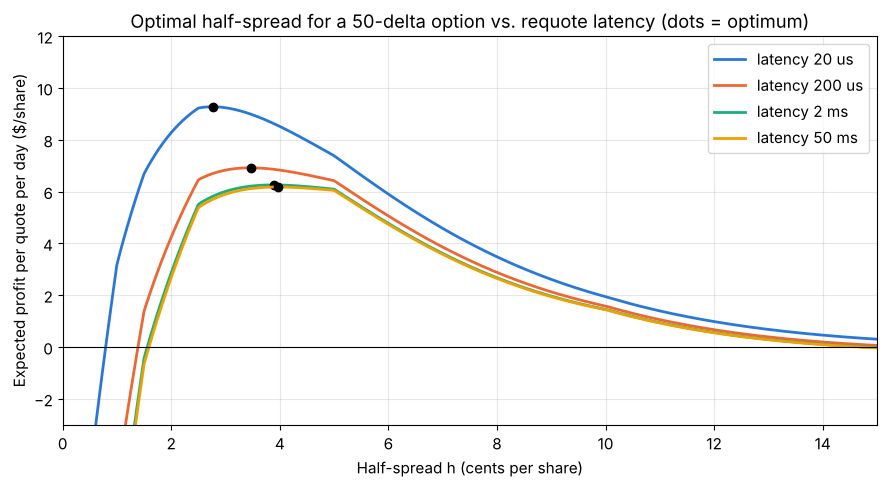

Optimal half-spread (cents): {'20 us': 2.77, '2000 us': 3.89, '50000 us': 3.97}
A slower firm must quote wider to survive the same flow -- and the wider quote loses the uninformed customer.
Speed is not a strategy on its own; it is what lets you quote the spread that wins the flow.


In [7]:
# Optimal half-spread: spread revenue from elastic uninformed flow minus sniping cost, per second.
A_arr, k_el = 0.05, 40.0      # uninformed arrivals/s at zero spread, elasticity per $ of half-spread
h_grid = np.linspace(0.001, 0.30, 1200)

def profit_rate(h, delta, L):
    revenue = A_arr * np.exp(-k_el * h) * h
    sniping = nu * p_lose_race(L) * np.array([pickoff_loss_jumps(delta, hh) for hh in np.atleast_1d(h)])
    return revenue - sniping

fig, ax = plt.subplots(figsize=(9, 5))
for L, lab in [(20e-6, "20 us"), (200e-6, "200 us"), (2e-3, "2 ms"), (50e-3, "50 ms")]:
    pr = profit_rate(h_grid, 0.5, L)
    ax.plot(h_grid * 100, pr * 6.5 * 3600, lw=2, label=f"latency {lab}")
    i = np.argmax(pr)
    ax.plot(h_grid[i] * 100, pr[i] * 6.5 * 3600, "o", color="k", ms=6)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlim(0, 15); ax.set_ylim(-3, 12)
ax.set_xlabel("Half-spread h (cents per share)"); ax.set_ylabel("Expected profit per quote per day ($/share)")
ax.set_title("Optimal half-spread for a 50-delta option vs. requote latency (dots = optimum)")
ax.legend(); plt.tight_layout(); plt.show()

h_opt = {L: h_grid[np.argmax(profit_rate(h_grid, 0.5, L))] for L in (20e-6, 2e-3, 50e-3)}
print("Optimal half-spread (cents):", {f"{L*1e6:.0f} us": round(float(h) * 100, 2) for L, h in h_opt.items()})
print("A slower firm must quote wider to survive the same flow -- and the wider quote loses the uninformed customer.")
print("Speed is not a strategy on its own; it is what lets you quote the spread that wins the flow.")

## 5. Delta hedging with real costs

**Sources:** El Karoui, Jeanblanc-Picqué & Shreve (1998), *Robustness of the Black and Scholes
Formula*, Math. Finance, for the P&L identity; Boyle & Emanuel (1980) and Derman & Kamal
(1999) for discrete-hedging error; Leland (1985) for proportional transaction costs; Whalley &
Wilmott (1997) for the asymptotically optimal no-trade band; Zakamouline (2006) for its
refinements.

### 5a. The fundamental P&L identity of option market making

Sell an option at implied vol $\sigma_i$ and delta-hedge it continuously using the
Black-Scholes delta at $\sigma_i$. If the underlying actually moves with volatility
$\sigma_r$, the hedged P&L is **path-dependent but has a closed form**:

$$
\text{P\&L}_T = \int_0^T e^{r(T-t)}\,\tfrac12 \Gamma_t S_t^2\,(\sigma_i^2 - \sigma_r^2)\,dt
$$

This is the whole business in one line. The market maker who sold the option *earns*
$\tfrac12\Gamma S^2 \sigma_i^2\,dt$ in theta and *pays* $\tfrac12\Gamma S^2 \sigma_r^2\,dt$ in
gamma, every instant, weighted by where the path spends its time. You do not need to know
where the stock goes; you need realized variance to be lower than what you sold it at, *where
your gamma is*. In discrete time the identity reads, path by path,
$\text{P\&L} \approx \sum_t \tfrac12 \Gamma_t S_t^2 \big(\sigma_i^2\,\delta t - (\delta S_t/S_t)^2\big)$,
and that discrete form is what we verify.

### 5b. Discrete hedging error scales like $1/\sqrt N$

With $N$ rebalances the P&L acquires a zero-mean error whose standard deviation falls like
$N^{-1/2}$ (Boyle-Emanuel). Derman & Kamal's rule of thumb: for an ATM option the hedge-error
standard deviation is roughly $\sqrt{\pi/4}\;\mathcal V\sigma/\sqrt N$ — about $0.9\,\mathcal{V}\sigma/\sqrt{N}$.

### 5c. Transaction costs scale like $\sqrt N$ — Leland

Each rebalance trades $|\delta\Delta| \approx \Gamma S\sigma\sqrt{\delta t}\sqrt{2/\pi}$ shares.
With a proportional round-trip cost $k$, the expected total cost over the life is, to first
order, exactly what you get by pricing the option at Leland's adjusted volatility

$$
\hat\sigma^2 = \sigma^2\left(1 + \sqrt{\tfrac{2}{\pi}}\,\frac{k}{\sigma\sqrt{\delta t}}\right)
$$

and subtracting the Black-Scholes price. Hedging more often lowers the error and raises
the cost: the market maker picks a point on that curve.

### 5d. Hedging to a band — Whalley-Wilmott

The utility-maximising policy is not "hedge every $\delta t$"; it is "do nothing while the
delta is inside a band around the Black-Scholes delta, and trade back to the *edge* of the
band when it leaves". Whalley & Wilmott's asymptotic bandwidth is

$$
H_t = \left(\frac{3}{2}\,\frac{e^{-r(T-t)}\,k_1\,S_t\,\Gamma_t^2}{\gamma}\right)^{1/3}
$$

with $k_1$ the one-way proportional cost and $\gamma$ the risk aversion. The band is wide
where gamma is large (hedging there is expensive) and narrow where it is small.

In [8]:
def hedge_short_option_on_paths(paths, times, K, T, sigma_hedge, kind="call", cost_oneway=0.0,
                                policy="time", band=None, gamma_ra=None):
    """Delta-hedge a SHORT option along pre-simulated paths.

    paths : (n_paths, n_steps+1) underlying prices, times : (n_steps+1,) in years from 0 to T.
    policy: 'time'  -> rebalance to BS delta at every step
            'band'  -> rebalance to BS delta only when |hedge - delta| > band (fixed band, in shares)
            'ww'    -> Whalley-Wilmott: band = (1.5 e^{-r tau} k S Gamma^2 / gamma)^{1/3}, trade to the band EDGE
    Returns dict with pnl, cost, and the discrete pathwise theory integral pieces.
    """
    n_paths, n1 = paths.shape
    S = paths[:, 0].copy()
    g0 = bs_greeks(S, K, T, r, q, sigma_hedge, kind)
    premium = g0["price"]
    hedge = g0["delta"].copy() if np.ndim(g0["delta"]) else np.full(n_paths, float(g0["delta"]))
    cost = cost_oneway * np.abs(hedge) * S
    cost_rebal = np.zeros(n_paths)      # rebalancing only -- the part Leland's formula is about (setup and unwind excluded)
    cash = premium - hedge * S - cost
    theo_carry = np.zeros(n_paths)      # sum of 1/2 Gamma S^2 sigma_i^2 dt  e^{r(T-t)}
    real_carry = np.zeros(n_paths)      # sum of 1/2 Gamma S^2 (dS/S)^2     e^{r(T-t)}
    n_trades = np.zeros(n_paths)
    for i in range(n1 - 1):
        t, dt = times[i], times[i + 1] - times[i]
        tau = T - t
        g = bs_greeks(S, K, tau, r, q, sigma_hedge, kind)
        S_new = paths[:, i + 1]
        disc = np.exp(r * (T - t))
        theo_carry += disc * 0.5 * g["gamma"] * S**2 * sigma_hedge**2 * dt
        real_carry += disc * 0.5 * g["gamma"] * S**2 * (S_new / S - 1.0)**2
        cash = cash * np.exp(r * dt) + hedge * S * (np.exp(q * dt) - 1.0)   # interest on cash, dividends on the hedge
        S = S_new
        tau_new = T - times[i + 1]
        if tau_new > 1e-12:
            gn = bs_greeks(S, K, tau_new, r, q, sigma_hedge, kind)
            target = gn["delta"]
            if policy == "time":
                new_hedge = target
            elif policy == "band":
                outside = np.abs(hedge - target) > band
                new_hedge = np.where(outside, target, hedge)
            elif policy == "ww":
                H = (1.5 * np.exp(-r * tau_new) * cost_oneway * S * gn["gamma"]**2 / gamma_ra) ** (1 / 3)
                above, below = hedge > target + H, hedge < target - H
                new_hedge = np.where(above, target + H, np.where(below, target - H, hedge))
            else:
                raise ValueError(policy)
            trade = new_hedge - hedge
            c = cost_oneway * np.abs(trade) * S
            cash -= trade * S + c
            cost += c; cost_rebal += c
            n_trades += (np.abs(trade) > 1e-12)
            hedge = new_hedge
    payoff = np.maximum(S - K, 0.0) if kind == "call" else np.maximum(K - S, 0.0)
    c = cost_oneway * np.abs(hedge) * S
    cost += c
    pnl = cash + hedge * S - c - payoff
    return dict(pnl=pnl, cost=cost, cost_rebal=cost_rebal, theo_carry=theo_carry, real_carry=real_carry, n_trades=n_trades, premium=float(np.mean(premium)))

def gbm_paths(n_paths, n_steps, T, sigma, rng, S_start=S0, mu=0.05):
    dt = T / n_steps
    Z = rng.standard_normal((n_paths, n_steps))
    logret = (mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
    return S_start * np.exp(np.concatenate([np.zeros((n_paths, 1)), np.cumsum(logret, axis=1)], axis=1))

# --- 5a: the identity, checked pathwise ---
rng = np.random.default_rng(5)
T_h, K_h, sig_i = 0.25, 100.0, 0.20
n_steps = 500
times = np.linspace(0, T_h, n_steps + 1)
results = {}
for sig_r in (0.14, 0.20, 0.26):
    paths = gbm_paths(4000, n_steps, T_h, sig_r, rng)
    out = hedge_short_option_on_paths(paths, times, K_h, T_h, sig_i, "call")
    theory = out["theo_carry"] - out["real_carry"]
    corr = np.corrcoef(out["pnl"], theory)[0, 1]
    results[sig_r] = (out["pnl"].mean(), theory.mean(), corr, out["pnl"].std())
    diff = out["pnl"] - theory
    assert abs(diff.mean()) < 3 * diff.std() / np.sqrt(len(diff)) + 0.01, "pathwise identity failed"
    print(f"sigma_real={sig_r:.2f}: mean hedged P&L {out['pnl'].mean():+.4f}, pathwise integral {theory.mean():+.4f}, "
          f"corr(P&L, integral)={corr:.4f}")
print("The hedged P&L is the gamma-weighted variance spread, path by path -- not just on average.")

sigma_real=0.14: mean hedged P&L +1.1877, pathwise integral +1.1873, corr(P&L, integral)=0.9993


sigma_real=0.20: mean hedged P&L +0.0019, pathwise integral +0.0017, corr(P&L, integral)=0.9932


sigma_real=0.26: mean hedged P&L -1.1938, pathwise integral -1.1951, corr(P&L, integral)=0.9983
The hedged P&L is the gamma-weighted variance spread, path by path -- not just on average.


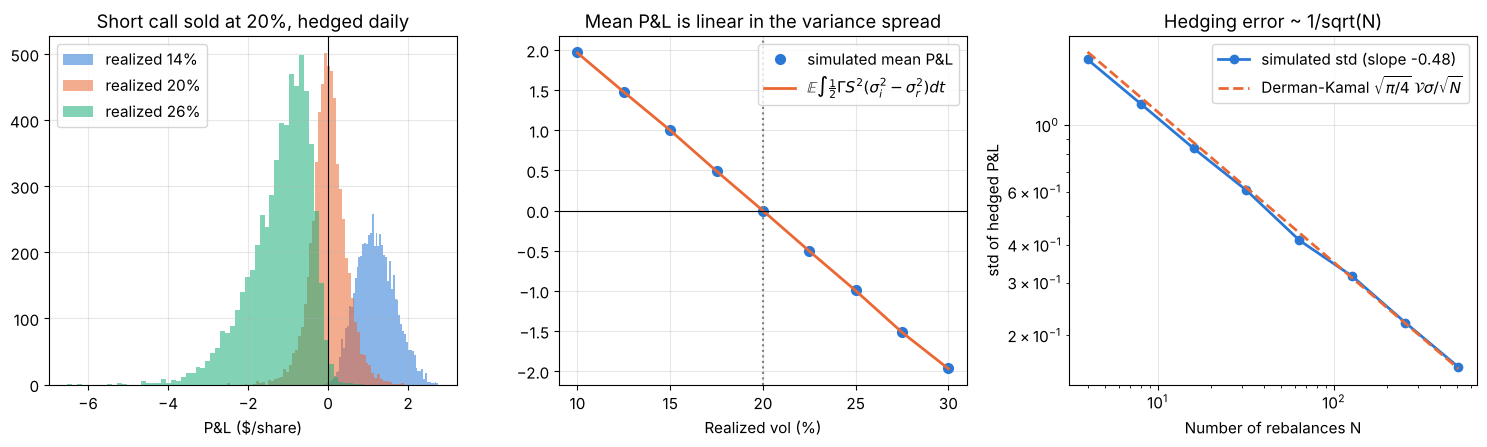

Log-log slope of hedge-error std vs N: -0.485  (theory -0.5)


In [9]:
# --- 5a/5b figures: P&L distributions, the mean vs realized vol, and the 1/sqrt(N) law ---
rng = np.random.default_rng(6)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

# (i) terminal P&L distributions for daily hedging at three realized vols
n_daily = int(round(T_h / DAY))
t_daily = np.linspace(0, T_h, n_daily + 1)
for sig_r in (0.14, 0.20, 0.26):
    paths = gbm_paths(6000, n_daily, T_h, sig_r, rng)
    out = hedge_short_option_on_paths(paths, t_daily, K_h, T_h, sig_i, "call")
    axes[0].hist(out["pnl"], bins=60, alpha=0.55, label=f"realized {sig_r:.0%}")
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_title(f"Short call sold at {sig_i:.0%}, hedged daily"); axes[0].set_xlabel("P&L ($/share)"); axes[0].legend()

# (ii) mean P&L vs realized vol -- simulation against the expected integral
sig_grid = np.linspace(0.10, 0.30, 9)
means, theos = [], []
for sig_r in sig_grid:
    paths = gbm_paths(3000, n_daily, T_h, sig_r, rng)
    out = hedge_short_option_on_paths(paths, t_daily, K_h, T_h, sig_i, "call")
    means.append(out["pnl"].mean()); theos.append((out["theo_carry"] - out["real_carry"]).mean())
axes[1].plot(sig_grid * 100, means, "o", ms=7, label="simulated mean P&L")
axes[1].plot(sig_grid * 100, theos, lw=2, label=r"$\mathbb{E}\int \frac{1}{2}\Gamma S^2(\sigma_i^2-\sigma_r^2)dt$")
axes[1].axvline(sig_i * 100, color="gray", ls=":"); axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("Realized vol (%)"); axes[1].set_title("Mean P&L is linear in the variance spread"); axes[1].legend()

# (iii) hedging-error std vs number of rebalances
Ns = np.array([4, 8, 16, 32, 64, 128, 256, 512])
stds = []
for N in Ns:
    tt = np.linspace(0, T_h, N + 1)
    paths = gbm_paths(3000, N, T_h, sig_i, rng)
    out = hedge_short_option_on_paths(paths, tt, K_h, T_h, sig_i, "call")
    stds.append(out["pnl"].std())
slope = np.polyfit(np.log(Ns), np.log(stds), 1)[0]
vega0 = bs_greeks(S0, K_h, T_h, r, q, sig_i)["vega"]
dk = np.sqrt(np.pi / 4) * vega0 * sig_i / np.sqrt(Ns)
axes[2].loglog(Ns, stds, "o-", lw=2, label=f"simulated std (slope {slope:.2f})")
axes[2].loglog(Ns, dk, "--", lw=2, label=r"Derman-Kamal $\sqrt{\pi/4}\,\mathcal{V}\sigma/\sqrt{N}$")
axes[2].set_xlabel("Number of rebalances N"); axes[2].set_ylabel("std of hedged P&L"); axes[2].set_title("Hedging error ~ 1/sqrt(N)"); axes[2].legend()
plt.tight_layout(); plt.show()
assert -0.62 < slope < -0.38, f"hedging error should scale like N^-1/2, got slope {slope:.2f}"
print(f"Log-log slope of hedge-error std vs N: {slope:.3f}  (theory -0.5)")

 N rebalances  Simulated mean rebalancing cost  Leland price adjustment  std of P&L
           13                           0.0538                   0.0566      0.9404
           26                           0.0784                   0.0797      0.6715
           63                           0.1250                   0.1235      0.4424
          126                           0.1757                   0.1735      0.3206
          252                           0.2496                   0.2433      0.2503
          504                           0.3570                   0.3400      0.2095
         1008                           0.5006                   0.4732      0.2206


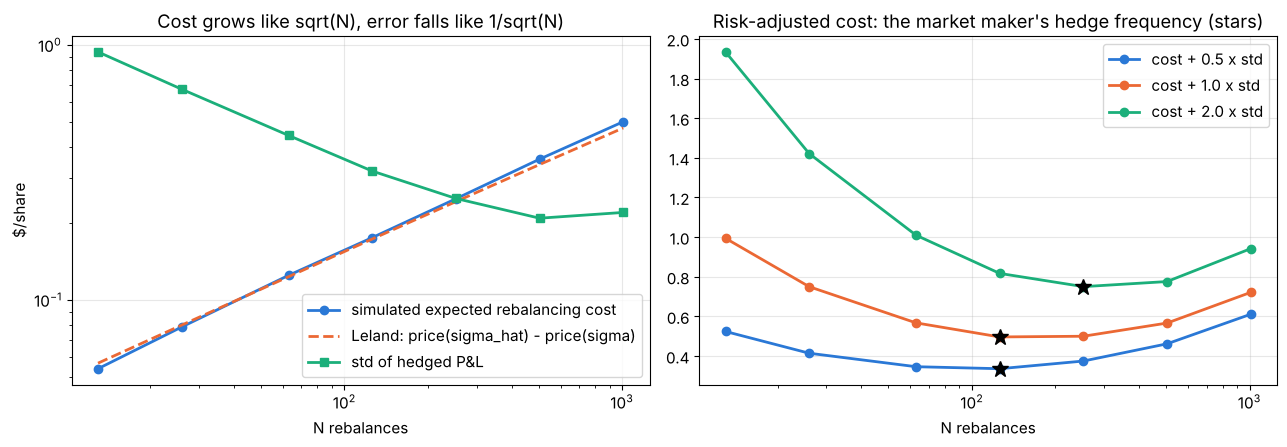

In [10]:
# --- 5c: Leland. Expected rebalancing cost from simulation vs. the Leland-vol price adjustment ---
rng = np.random.default_rng(7)
k_round = 0.0010                     # 10 bp round trip, i.e. 5 bp each way -- a liquid large-cap
Ns = np.array([13, 26, 63, 126, 252, 504, 1008])
sim_cost, lel_cost, sim_std = [], [], []
for N in Ns:
    tt = np.linspace(0, T_h, N + 1)
    paths = gbm_paths(3000, N, T_h, sig_i, rng)
    out = hedge_short_option_on_paths(paths, tt, K_h, T_h, sig_i, "call", cost_oneway=k_round / 2)
    sim_cost.append(out["cost_rebal"].mean()); sim_std.append(out["pnl"].std())
    dt = T_h / N
    sigma_leland = np.sqrt(sig_i**2 * (1 + np.sqrt(2 / np.pi) * k_round / (sig_i * np.sqrt(dt))))
    lel_cost.append(bs_price(S0, K_h, T_h, r, q, sigma_leland) - bs_price(S0, K_h, T_h, r, q, sig_i))
sim_cost, lel_cost, sim_std = map(np.array, (sim_cost, lel_cost, sim_std))
tbl = pd.DataFrame({"N rebalances": Ns, "Simulated mean rebalancing cost": sim_cost.round(4),
                    "Leland price adjustment": lel_cost.round(4), "std of P&L": sim_std.round(4)})
print(tbl.to_string(index=False))
rel = np.abs(sim_cost - lel_cost) / lel_cost
assert np.all(rel[Ns >= 63] < 0.25), "Leland adjustment and simulated cost disagree by more than 25%"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].loglog(Ns, sim_cost, "o-", lw=2, label="simulated expected rebalancing cost")
axes[0].loglog(Ns, lel_cost, "--", lw=2, label="Leland: price(sigma_hat) - price(sigma)")
axes[0].loglog(Ns, sim_std, "s-", lw=2, label="std of hedged P&L")
axes[0].set_xlabel("N rebalances"); axes[0].set_ylabel("$/share"); axes[0].set_title("Cost grows like sqrt(N), error falls like 1/sqrt(N)"); axes[0].legend()
for lam in (0.5, 1.0, 2.0):
    obj = sim_cost + lam * sim_std
    axes[1].semilogx(Ns, obj, "o-", lw=2, label=f"cost + {lam} x std")
    axes[1].plot(Ns[np.argmin(obj)], obj.min(), "k*", ms=12)
axes[1].set_xlabel("N rebalances"); axes[1].set_title("Risk-adjusted cost: the market maker's hedge frequency (stars)"); axes[1].legend()
plt.tight_layout(); plt.show()

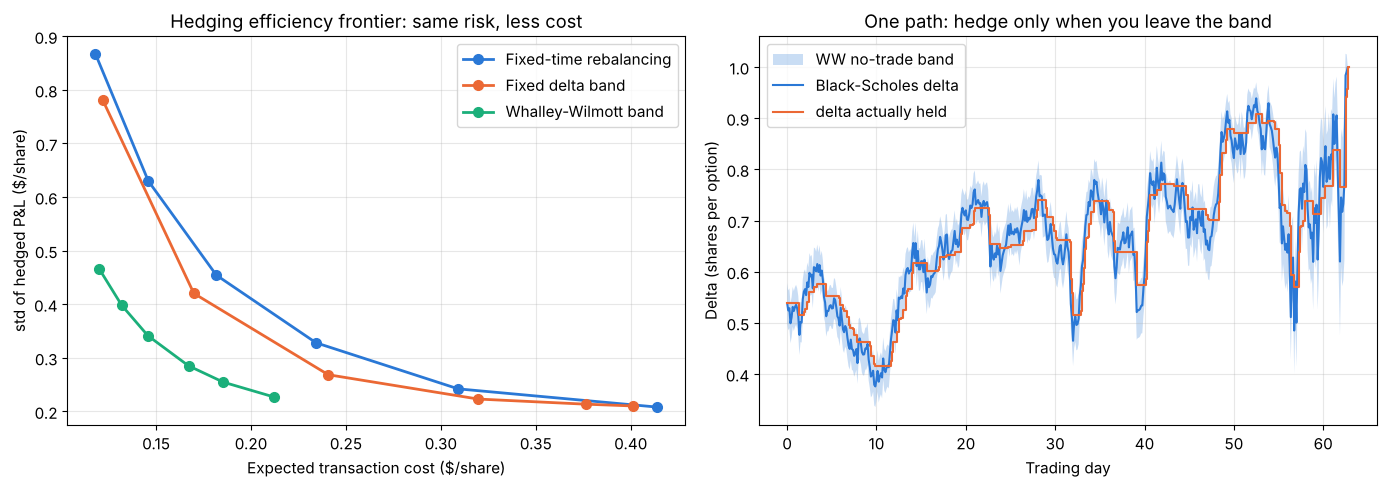

Trades per path -- fixed-time: 15..499;  Whalley-Wilmott: 108..236
The band policies sit below the fixed-time curve: for the same P&L dispersion they pay less,
because they don't trade when a move is about to be hedged away by the next move anyway.


In [11]:
# --- 5d: time-based vs fixed-band vs Whalley-Wilmott, on identical paths ---
rng = np.random.default_rng(8)
N_fine = 504                           # twice a day over a quarter: the band policies are *allowed* to look this often
tt = np.linspace(0, T_h, N_fine + 1)
paths = gbm_paths(2500, N_fine, T_h, sig_i, rng)
k1 = k_round / 2

frontier = {"time": [], "band": [], "ww": []}
for every in (1, 2, 4, 8, 16, 32):     # rebalance every `every` fine steps
    sub = paths[:, ::every]; tsub = tt[::every]
    out = hedge_short_option_on_paths(sub, tsub, K_h, T_h, sig_i, "call", cost_oneway=k1)
    frontier["time"].append((out["cost"].mean(), out["pnl"].std(), out["n_trades"].mean(), f"every {every}"))
for band in (0.005, 0.01, 0.02, 0.04, 0.08, 0.15):
    out = hedge_short_option_on_paths(paths, tt, K_h, T_h, sig_i, "call", cost_oneway=k1, policy="band", band=band)
    frontier["band"].append((out["cost"].mean(), out["pnl"].std(), out["n_trades"].mean(), f"band {band}"))
for gamma_ra in (0.5, 1.0, 2.0, 5.0, 10.0, 25.0):
    out = hedge_short_option_on_paths(paths, tt, K_h, T_h, sig_i, "call", cost_oneway=k1, policy="ww", gamma_ra=gamma_ra)
    frontier["ww"].append((out["cost"].mean(), out["pnl"].std(), out["n_trades"].mean(), f"gamma {gamma_ra}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for key, lab in [("time", "Fixed-time rebalancing"), ("band", "Fixed delta band"), ("ww", "Whalley-Wilmott band")]:
    pts = np.array([(c, s) for c, s, _, _ in frontier[key]])
    axes[0].plot(pts[:, 0], pts[:, 1], "o-", lw=2, ms=7, label=lab)
axes[0].set_xlabel("Expected transaction cost ($/share)"); axes[0].set_ylabel("std of hedged P&L ($/share)")
axes[0].set_title("Hedging efficiency frontier: same risk, less cost"); axes[0].legend()

# one path, the band drawn around the BS delta, with the WW hedge actually held
rng2 = np.random.default_rng(9)
one = gbm_paths(1, N_fine, T_h, sig_i, rng2)
S_path = one[0]
delta_bs = np.array([bs_greeks(S_path[i], K_h, T_h - tt[i], r, q, sig_i)["delta"] for i in range(N_fine)])
gam = np.array([bs_greeks(S_path[i], K_h, T_h - tt[i], r, q, sig_i)["gamma"] for i in range(N_fine)])
H = (1.5 * np.exp(-r * (T_h - tt[:N_fine])) * k1 * S_path[:N_fine] * gam**2 / 2.0) ** (1 / 3)
held = np.empty(N_fine); held[0] = delta_bs[0]
for i in range(1, N_fine):
    h_prev = held[i - 1]
    held[i] = delta_bs[i] + H[i] if h_prev > delta_bs[i] + H[i] else (delta_bs[i] - H[i] if h_prev < delta_bs[i] - H[i] else h_prev)
axes[1].fill_between(tt[:N_fine] * 252, delta_bs - H, delta_bs + H, alpha=0.25, label="WW no-trade band")
axes[1].plot(tt[:N_fine] * 252, delta_bs, lw=1.5, label="Black-Scholes delta")
axes[1].step(tt[:N_fine] * 252, held, lw=1.5, where="post", label="delta actually held")
axes[1].set_xlabel("Trading day"); axes[1].set_ylabel("Delta (shares per option)"); axes[1].set_title("One path: hedge only when you leave the band"); axes[1].legend()
plt.tight_layout(); plt.show()

ww_tr = np.array([n for _, _, n, _ in frontier["ww"]]); tm_tr = np.array([n for _, _, n, _ in frontier["time"]])
print(f"Trades per path -- fixed-time: {tm_tr.min():.0f}..{tm_tr.max():.0f};  Whalley-Wilmott: {ww_tr.min():.0f}..{ww_tr.max():.0f}")
print("The band policies sit below the fixed-time curve: for the same P&L dispersion they pay less,")
print("because they don't trade when a move is about to be hedged away by the next move anyway.")

## 6. The surface as the quoting engine

**Sources:** Gatheral (2004), *A parsimonious arbitrage-free implied volatility
parameterization* (the SVI model); Gatheral & Jacquier (2014), *Arbitrage-free SVI volatility
surfaces*, Quantitative Finance; Durrleman (2003) for the butterfly condition; Derman (1999),
*Regimes of Volatility*, for sticky-strike vs sticky-delta; Heston (1993) for the "true" market
we generate.

Nobody quotes 2,000 options independently. A desk fits a **low-dimensional parametric smile
per expiry** to the market, and every quote is the parametric value plus a spread plus a
skew (Section 9). Three reasons:

1. **Noise reduction.** Each individual option's mid is a noisy observation of the surface;
   the fit averages over the whole strike range.
2. **Arbitrage-freeness is a property of the surface, not of a price.** If your quotes
   violate a butterfly or calendar condition someone will trade the arbitrage against you.
   A parametrisation makes those conditions checkable (and, with constraints, enforceable).
3. **Hedge ratios come from the surface's dynamics**, not from Black-Scholes. How the smile
   moves when spot moves ("sticky strike" vs "sticky delta/moneyness") changes the delta you
   should hedge with — by a lot, for skewed names.

**Raw SVI.** In total implied variance $w = \sigma^2 T$ against log-moneyness $k = \ln(K/F)$:

$$
w(k) = a + b\left(\rho\,(k - m) + \sqrt{(k-m)^2 + \sigma^2}\right)
$$

Five parameters; $a$ is the level, $b$ the wing slope, $\rho$ the skew (asymmetry), $m$ the
horizontal shift, $\sigma$ the ATM curvature.

**Butterfly (no negative density) condition — Durrleman:**
$$
g(k) = \left(1 - \frac{k\,w'}{2w}\right)^2 - \frac{w'^2}{4}\left(\frac1w + \frac14\right) + \frac{w''}{2} \;\ge\; 0
$$

**Calendar condition:** $w(k, T_2) \ge w(k, T_1)$ for $T_2 > T_1$ at every $k$.

In [12]:
# --- A "true" market from Heston, so the smile has a real reason to exist. Same Little-Trap form as the VIX notebook. ---
kappa_h, theta_h, xi_h, rho_h, v0_h = 2.0, 0.045, 0.6, -0.7, 0.035

def heston_cf(u, S, T, r, q, kappa, theta, xi, rho, v0):
    x = np.log(S); a = kappa * theta; b = kappa
    d = np.sqrt((rho * xi * 1j * u - b)**2 + xi**2 * (1j * u + u**2))
    g = (b - rho * xi * 1j * u - d) / (b - rho * xi * 1j * u + d)
    C = (r - q) * 1j * u * T + (a / xi**2) * ((b - rho * xi * 1j * u - d) * T - 2 * np.log((1 - g * np.exp(-d * T)) / (1 - g)))
    D = ((b - rho * xi * 1j * u - d) / xi**2) * ((1 - np.exp(-d * T)) / (1 - g * np.exp(-d * T)))
    return np.exp(C + D * v0 + 1j * u * x)

def heston_call(S, K, T, r, q, kappa=kappa_h, theta=theta_h, xi=xi_h, rho=rho_h, v0=v0_h):
    def P(j):
        def integrand(u):
            if j == 1:
                cf = heston_cf(u - 1j, S, T, r, q, kappa, theta, xi, rho, v0) / heston_cf(-1j, S, T, r, q, kappa, theta, xi, rho, v0)
            else:
                cf = heston_cf(u, S, T, r, q, kappa, theta, xi, rho, v0)
            return np.real(np.exp(-1j * u * np.log(K)) * cf / (1j * u))
        return 0.5 + quad(integrand, 1e-8, 200, limit=200)[0] / np.pi
    return S * np.exp(-q * T) * P(1) - K * np.exp(-r * T) * P(2)

# Sanity: Heston with xi -> 0 and v0 = theta must collapse to Black-Scholes.
bs_ref = bs_price(S0, 100.0, 0.5, r, q, np.sqrt(0.04))
hz = heston_call(S0, 100.0, 0.5, r, q, kappa=2.0, theta=0.04, xi=1e-4, rho=0.0, v0=0.04)
assert abs(hz - bs_ref) < 1e-3, (hz, bs_ref)
print(f"Heston(xi->0) = {hz:.5f}  vs  Black-Scholes = {bs_ref:.5f}  -- pricer is wired correctly")

# The market the desk sees: four expiries, 15 strikes each, mids observed with noise, quoted with a bid/ask in vol.
rng = np.random.default_rng(10)
mkt_expiries = np.array([1 / 12, 3 / 12, 6 / 12, 1.0])
market = {}
for T in mkt_expiries:
    F = S0 * np.exp((r - q) * T)
    k_grid = np.linspace(-2.0, 2.0, 15) * np.sqrt(theta_h) * np.sqrt(T) * 1.3
    Ks = F * np.exp(k_grid)
    true_iv = np.array([implied_vol(heston_call(S0, K, T, r, q), S0, K, T, r, q) for K in Ks])
    noise = rng.normal(0, 0.003, size=Ks.size)                 # 0.3 vol pt observation noise
    half = 0.004 + 0.006 * np.abs(k_grid) / k_grid.max()       # bid/ask half-width in vol: 0.4 pt ATM, 1 pt in the wings
    market[T] = dict(K=Ks, k=k_grid, true_iv=true_iv, mid_iv=true_iv + noise, half=half, F=F)
print("Synthetic option market built:", {f"{T:.2f}y": f"{len(m['K'])} strikes" for T, m in market.items()})

Heston(xi->0) = 6.09013  vs  Black-Scholes = 6.09013  -- pricer is wired correctly


Synthetic option market built: {'0.08y': '15 strikes', '0.25y': '15 strikes', '0.50y': '15 strikes', '1.00y': '15 strikes'}


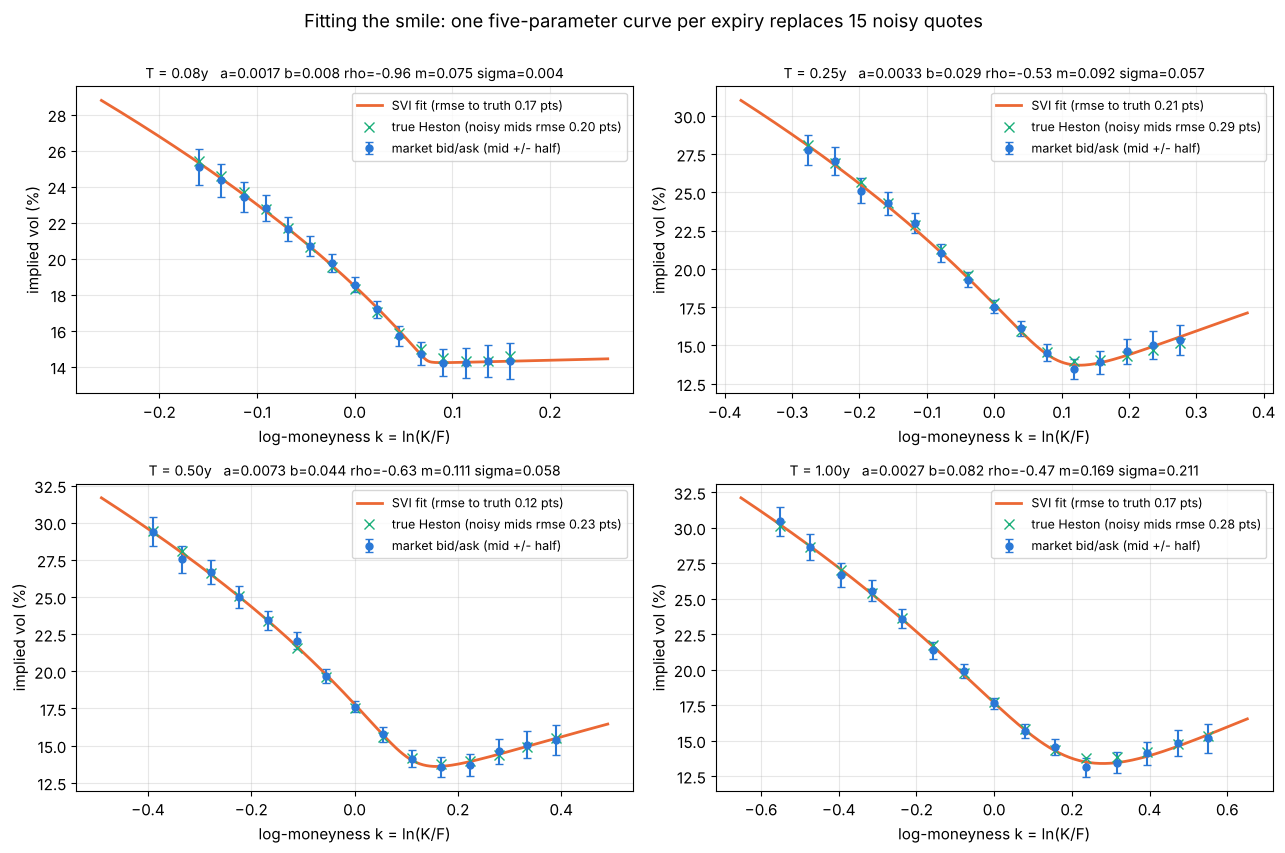

In [13]:
def svi_w(k, p):
    a, b, rho, m, s = p
    return a + b * (rho * (k - m) + np.sqrt((k - m)**2 + s**2))

def svi_w1(k, p):
    a, b, rho, m, s = p
    return b * (rho + (k - m) / np.sqrt((k - m)**2 + s**2))

def svi_w2(k, p):
    a, b, rho, m, s = p
    return b * s**2 / ((k - m)**2 + s**2) ** 1.5

def fit_svi(k, w_mid, weights, T):
    """Least squares in total variance, weighted by the inverse bid/ask width. Bounds keep it in the sane region
    (Gatheral-Jacquier: b >= 0, |rho| < 1, sigma > 0, a + b sigma sqrt(1-rho^2) >= 0)."""
    def resid(p):
        pen = 1000.0 * max(0.0, -(p[0] + p[1] * p[4] * np.sqrt(1 - p[2]**2)))   # keep min variance non-negative
        return np.concatenate([(svi_w(k, p) - w_mid) * weights, [pen]])
    best = None
    for rho0 in (-0.7, -0.3, 0.0):
        for s0 in (0.05, 0.2):
            p0 = [w_mid.min() * 0.8, 0.1, rho0, 0.0, s0]
            res = least_squares(resid, p0, bounds=([-1, 0, -0.999, -1, 1e-4], [1, 5, 0.999, 1, 2]))
            if best is None or res.cost < best.cost:
                best = res
    return best.x

def durrleman_g(k, p):
    w, w1, w2 = svi_w(k, p), svi_w1(k, p), svi_w2(k, p)
    return (1 - k * w1 / (2 * w))**2 - (w1**2 / 4) * (1 / w + 0.25) + w2 / 2

svi_params = {}
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for ax, T in zip(axes.ravel(), mkt_expiries):
    m = market[T]
    w_mid = m["mid_iv"]**2 * T
    p = fit_svi(m["k"], w_mid, 1.0 / m["half"], T)
    svi_params[T] = p
    kk = np.linspace(m["k"].min() - 0.1, m["k"].max() + 0.1, 300)
    fit_iv = np.sqrt(svi_w(kk, p) / T)
    rmse_fit = np.sqrt(np.mean((np.sqrt(svi_w(m["k"], p) / T) - m["true_iv"])**2))
    rmse_mid = np.sqrt(np.mean((m["mid_iv"] - m["true_iv"])**2))
    assert rmse_fit < rmse_mid, "the SVI fit should be closer to the truth than the raw noisy mids"
    ax.errorbar(m["k"], m["mid_iv"] * 100, yerr=m["half"] * 100, fmt="o", ms=5, capsize=3, color=PALETTE[0], label="market bid/ask (mid +/- half)")
    ax.plot(kk, fit_iv * 100, lw=2, color=PALETTE[1], label=f"SVI fit (rmse to truth {rmse_fit*100:.2f} pts)")
    ax.plot(m["k"], m["true_iv"] * 100, "x", ms=7, color=PALETTE[2], label=f"true Heston (noisy mids rmse {rmse_mid*100:.2f} pts)")
    ax.set_title(f"T = {T:.2f}y   a={p[0]:.4f} b={p[1]:.3f} rho={p[2]:.2f} m={p[3]:.3f} sigma={p[4]:.3f}", fontsize=10)
    ax.set_xlabel("log-moneyness k = ln(K/F)"); ax.set_ylabel("implied vol (%)"); ax.legend(fontsize=9)
fig.suptitle("Fitting the smile: one five-parameter curve per expiry replaces 15 noisy quotes", y=1.0)
plt.tight_layout(); plt.show()

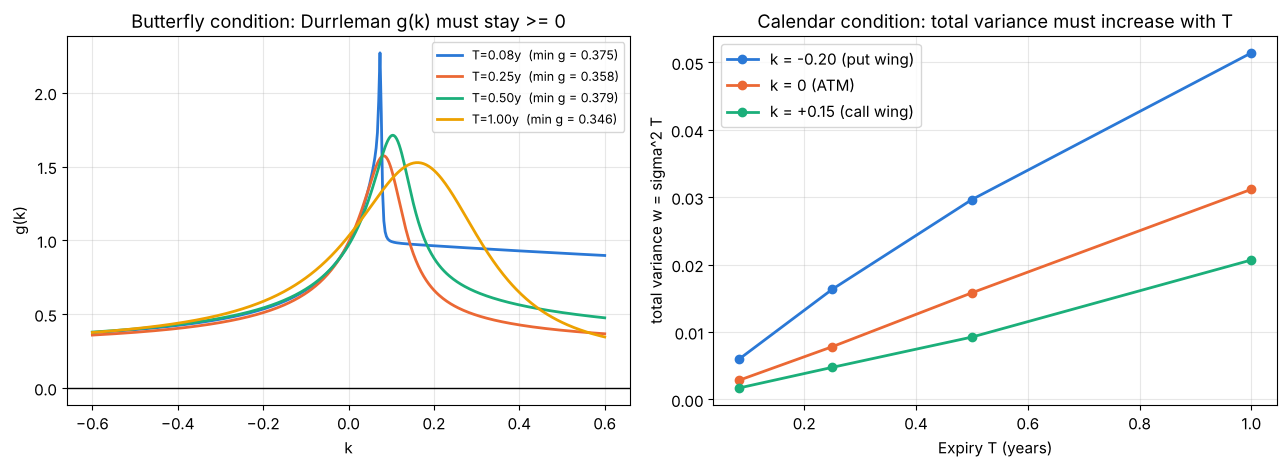

Butterfly condition satisfied on all four fitted slices: True
Calendar condition satisfied at three fixed log-moneyness levels.
A desk recomputes exactly these two checks every time the fit updates -- a quote off an arbitrageable surface is a gift.


In [14]:
# --- No-arbitrage checks on the fitted surface ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
kk = np.linspace(-0.6, 0.6, 400)
all_ok = True
for T in mkt_expiries:
    g = durrleman_g(kk, svi_params[T])
    all_ok &= bool(np.all(g > -1e-10))
    axes[0].plot(kk, g, lw=2, label=f"T={T:.2f}y  (min g = {g.min():.3f})")
axes[0].axhline(0, color="k", lw=1); axes[0].set_xlabel("k"); axes[0].set_ylabel("g(k)")
axes[0].set_title("Butterfly condition: Durrleman g(k) must stay >= 0"); axes[0].legend(fontsize=9)

for kfix, lab in [(-0.2, "k = -0.20 (put wing)"), (0.0, "k = 0 (ATM)"), (0.15, "k = +0.15 (call wing)")]:
    ws = [svi_w(kfix, svi_params[T]) for T in mkt_expiries]
    axes[1].plot(mkt_expiries, ws, "o-", lw=2, label=lab)
    assert np.all(np.diff(ws) > 0), f"calendar arbitrage at {lab}"
axes[1].set_xlabel("Expiry T (years)"); axes[1].set_ylabel("total variance w = sigma^2 T")
axes[1].set_title("Calendar condition: total variance must increase with T"); axes[1].legend()
plt.tight_layout(); plt.show()
print("Butterfly condition satisfied on all four fitted slices:", all_ok)
print("Calendar condition satisfied at three fixed log-moneyness levels.")
print("A desk recomputes exactly these two checks every time the fit updates -- a quote off an arbitrageable surface is a gift.")

### Sticky strike vs. sticky delta: which delta do you hedge?

Black-Scholes delta assumes the implied vol of *this strike* does not change when spot moves
(**sticky strike**). Index and single-stock smiles mostly do not behave that way: when spot
falls, the vol at a *fixed strike* rises because that strike is now closer to the money on a
skewed smile (**sticky delta / sticky moneyness** — the smile is a function of $k = \ln(K/F)$,
not of $K$). The hedge ratio must include the vol move induced by the spot move:

$$
\Delta_{\text{total}} = \Delta_{BS} + \mathcal V\,\frac{\partial\sigma}{\partial S}, \qquad
\text{sticky delta:}\;\; \frac{\partial\sigma}{\partial S} = -\frac{1}{S}\frac{\partial\sigma}{\partial k}
$$

With a negative skew ($\partial\sigma/\partial k < 0$) this *raises* the delta of every option.
A desk short 10,000 25-delta puts that hedges with the Black-Scholes delta in a sticky-delta
market is carrying unintended short delta on every down move. Hull & White (2017) estimate the
*minimum-variance* delta empirically and find it sits between the two regimes for equity
indices, closer to sticky-delta.

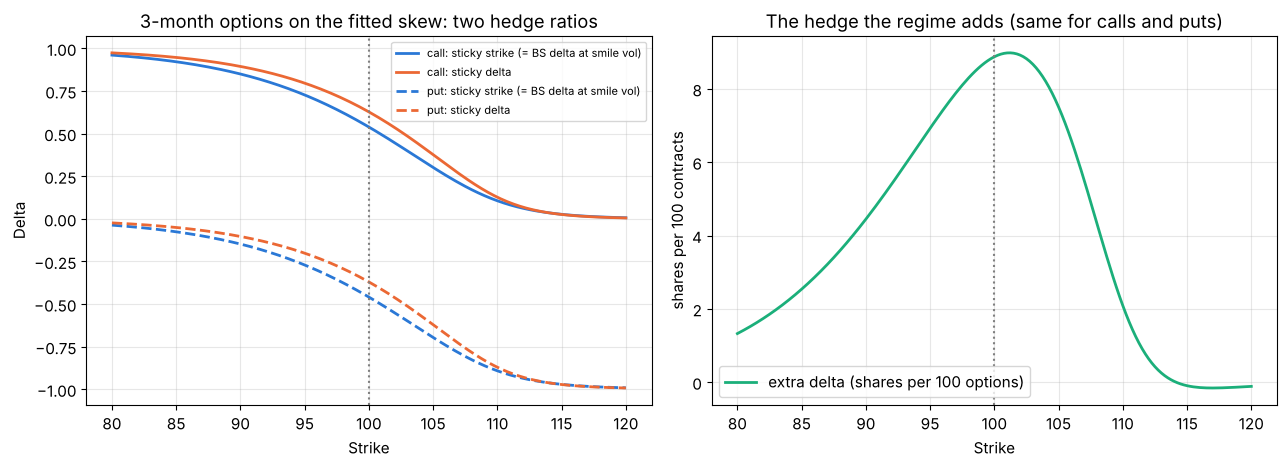

25-delta put (K~94): sticky-strike delta -0.248, sticky-delta adds +0.065. Short 10,000 of them and hedge with the wrong regime: 65,418 shares of unintended delta.


In [15]:
T_sd = 3 / 12
p = svi_params[T_sd]; m = market[T_sd]; F = m["F"]
Ks = np.linspace(80, 120, 161)
k = np.log(Ks / F)
w, w1 = svi_w(k, p), svi_w1(k, p)
sig = np.sqrt(w / T_sd)
dsig_dk = w1 / (2 * sig * T_sd)
dsig_dS_sticky_delta = -dsig_dk / S0

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for kind, ls in (("call", "-"), ("put", "--")):
    g = bs_greeks(S0, Ks, T_sd, r, q, sig, kind)
    d_ss = g["delta"]
    d_sd = g["delta"] + g["vega"] * dsig_dS_sticky_delta
    axes[0].plot(Ks, d_ss, ls, lw=2, color=PALETTE[0], label=f"{kind}: sticky strike (= BS delta at smile vol)")
    axes[0].plot(Ks, d_sd, ls, lw=2, color=PALETTE[1], label=f"{kind}: sticky delta")
    if kind == "put":
        axes[1].plot(Ks, (d_sd - d_ss) * 100, lw=2, color=PALETTE[2], label="extra delta (shares per 100 options)")
axes[0].axvline(S0, color="gray", ls=":"); axes[0].set_xlabel("Strike"); axes[0].set_ylabel("Delta"); axes[0].legend(fontsize=8)
axes[0].set_title("3-month options on the fitted skew: two hedge ratios")
axes[1].axvline(S0, color="gray", ls=":"); axes[1].set_xlabel("Strike"); axes[1].set_ylabel("shares per 100 contracts")
axes[1].set_title("The hedge the regime adds (same for calls and puts)"); axes[1].legend()
plt.tight_layout(); plt.show()

i25 = np.argmin(np.abs(bs_greeks(S0, Ks, T_sd, r, q, sig, "put")["delta"] + 0.25))
extra = (bs_greeks(S0, Ks[i25], T_sd, r, q, sig[i25], "put")["vega"] * dsig_dS_sticky_delta[i25])
print(f"25-delta put (K~{Ks[i25]:.0f}): sticky-strike delta {bs_greeks(S0, Ks[i25], T_sd, r, q, sig[i25], 'put')['delta']:.3f}, "
      f"sticky-delta adds {extra:+.3f}. Short 10,000 of them and hedge with the wrong regime: {abs(extra)*10000*100:,.0f} shares of unintended delta.")

## 7. Who is on the other side: sequential-trade learning and flow segmentation

**Sources:** Glosten & Milgrom (1985), *Bid, Ask and Transaction Prices in a Specialist Market
with Heterogeneously Informed Traders*, JFE; Easley, O'Hara & Srinivas (1998) for informed
trading in options specifically; Huang & Stoll (1996) for the effective/realized spread
decomposition used in Section 10.

The simplest model that produces a spread from information alone: the asset is worth $V_H$
or $V_L$ with equal prior probability; a fraction $\alpha$ of arriving traders know which, the
rest buy or sell at random. The market maker sets the ask at $\mathbb E[V\,|\,\text{buy}]$ and
the bid at $\mathbb E[V\,|\,\text{sell}]$, earning zero expected profit per trade:

$$
\text{ask} - \text{bid} \;=\; \alpha\,(V_H - V_L)
$$

Two things follow that matter enormously for how the large firms are organised:

1. **The spread is a price for information asymmetry, not for inventory.** Even a
   risk-neutral market maker with no inventory cost quotes a spread, and it scales linearly
   with the informed fraction.
2. **Flow that can be identified as uninformed can be quoted tighter.** This is the economic
   basis of *wholesaling*: a retail broker routes its customers' marketable options orders to
   a wholesaler (Citadel Securities, Susquehanna's execution affiliate, Wolverine, and a few
   others appear on the Rule 606 disclosures of the large retail brokers) who, knowing the
   flow's $\alpha$ is low, fills it *inside* the exchange's displayed spread ("price
   improvement") and still earns more per trade than it would on anonymous exchange flow —
   because the alternative was quoting the blended $\alpha$ of everyone. Whether the customer
   or the wholesaler captures more of that gain is the payment-for-order-flow debate.

Sequential trades update the belief; the quotes converge to the true value and the spread
closes. The *speed* of that convergence is what an informed trader is racing against.

alpha=0.3: formula bid/ask 99.7000/100.3000, spread 0.6000 = alpha(V_H-V_L) = 0.6000
           MC   E[V|sell]/E[V|buy] 99.6986/100.2974


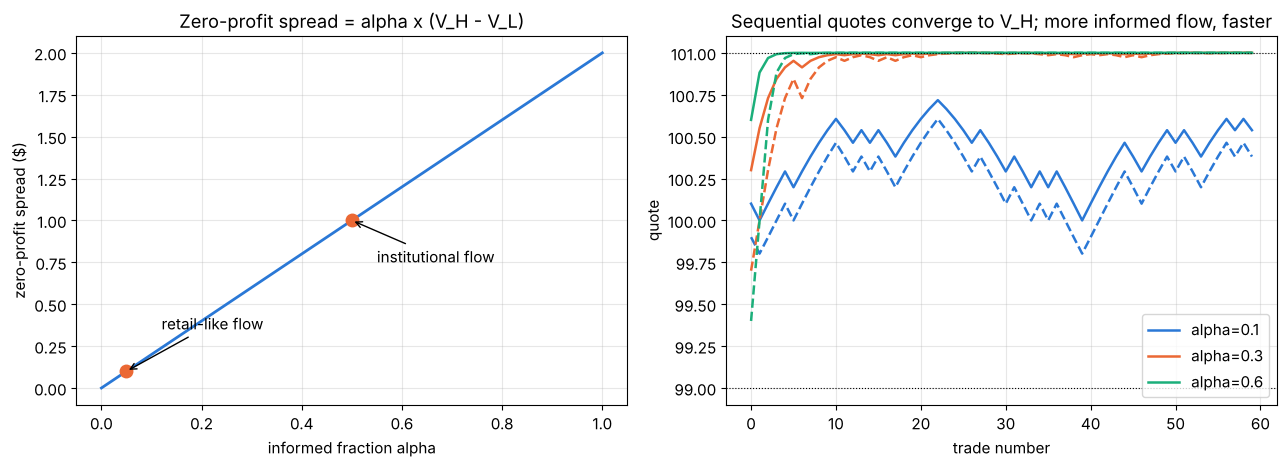

         Flow segment  informed fraction alpha  zero-profit spread ($)  spread relative to blended
  Retail (wholesaled)                     0.05                     0.1                        0.25
Blended exchange flow                     0.20                     0.4                        1.00
   Institutional / HF                     0.50                     1.0                        2.50

This is why segmenting flow is worth paying for: the retail segment can be quoted at a quarter of the blended spread
and still clear the information cost. The wholesaler's edge is knowing alpha, not knowing V.


In [16]:
V_H, V_L = 101.0, 99.0

def gm_quotes(p_high, alpha):
    """Glosten-Milgrom quotes given current belief p_high = P(V = V_H)."""
    p_buy_H, p_buy_L = (1 + alpha) / 2, (1 - alpha) / 2
    p_H_buy  = p_high * p_buy_H / (p_high * p_buy_H + (1 - p_high) * p_buy_L)
    p_H_sell = p_high * p_buy_L / (p_high * p_buy_L + (1 - p_high) * p_buy_H)
    ask = p_H_buy * V_H + (1 - p_H_buy) * V_L
    bid = p_H_sell * V_H + (1 - p_H_sell) * V_L
    return bid, ask, p_H_buy, p_H_sell

# Check the static spread formula against a brute-force conditional expectation
rng = np.random.default_rng(11)
alpha_chk = 0.3
V = np.where(rng.random(400_000) < 0.5, V_H, V_L)
informed = rng.random(V.size) < alpha_chk
buy = np.where(informed, V == V_H, rng.random(V.size) < 0.5)
mc_ask, mc_bid = V[buy].mean(), V[~buy].mean()
bid0, ask0, _, _ = gm_quotes(0.5, alpha_chk)
print(f"alpha={alpha_chk}: formula bid/ask {bid0:.4f}/{ask0:.4f}, spread {ask0-bid0:.4f} = alpha(V_H-V_L) = {alpha_chk*(V_H-V_L):.4f}")
print(f"           MC   E[V|sell]/E[V|buy] {mc_bid:.4f}/{mc_ask:.4f}")
assert abs(mc_ask - ask0) < 0.01 and abs(mc_bid - bid0) < 0.01

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
alphas = np.linspace(0, 1, 101)
axes[0].plot(alphas, alphas * (V_H - V_L), lw=2)
axes[0].set_xlabel("informed fraction alpha"); axes[0].set_ylabel("zero-profit spread ($)")
axes[0].set_title("Zero-profit spread = alpha x (V_H - V_L)")
for a_ret, a_inst, lab in [(0.05, 0.5, "retail vs institutional")]:
    axes[0].plot([a_ret, a_inst], [a_ret * 2, a_inst * 2], "o", ms=9, color=PALETTE[1])
    axes[0].annotate("retail-like flow", (a_ret, a_ret * 2), xytext=(0.12, 0.35), arrowprops=dict(arrowstyle="->"))
    axes[0].annotate("institutional flow", (a_inst, a_inst * 2), xytext=(0.55, 0.75), arrowprops=dict(arrowstyle="->"))

# Sequential learning: three alphas, true value V_H, 60 trades each
n_tr = 60
for alpha, col in zip((0.1, 0.3, 0.6), PALETTE[:3]):
    rng = np.random.default_rng(12)
    p_high = 0.5; bids, asks = [], []
    for _ in range(n_tr):
        bid, ask, pHb, pHs = gm_quotes(p_high, alpha)
        bids.append(bid); asks.append(ask)
        is_inf = rng.random() < alpha
        buy = True if is_inf else (rng.random() < 0.5)     # truth is V_H, so informed always buy
        p_high = pHb if buy else pHs
    axes[1].plot(asks, color=col, lw=1.8, label=f"alpha={alpha}")
    axes[1].plot(bids, color=col, lw=1.8, ls="--")
axes[1].axhline(V_H, color="k", lw=0.8, ls=":"); axes[1].axhline(V_L, color="k", lw=0.8, ls=":")
axes[1].set_xlabel("trade number"); axes[1].set_ylabel("quote"); axes[1].legend()
axes[1].set_title("Sequential quotes converge to V_H; more informed flow, faster")
plt.tight_layout(); plt.show()

seg = pd.DataFrame({
    "Flow segment": ["Retail (wholesaled)", "Blended exchange flow", "Institutional / HF"],
    "informed fraction alpha": [0.05, 0.20, 0.50],
    "zero-profit spread ($)": [0.05 * 2, 0.20 * 2, 0.50 * 2],
})
seg["spread relative to blended"] = (seg["zero-profit spread ($)"] / 0.4).round(2)
print(seg.to_string(index=False))
print("\nThis is why segmenting flow is worth paying for: the retail segment can be quoted at a quarter of the blended spread")
print("and still clear the information cost. The wholesaler's edge is knowing alpha, not knowing V.")

## 8. The strategies the large firms are known for

Market making is the engine; these are the trades that the engine's by-products (a view on
the surface, cheap access to flow, a financing book, a correlation book) make possible. Each
subsection states the identity the trade exploits, implements it, and shows what it is
*really* a bet on.

### 8a. Dispersion: trading index vol against its components

**Sources:** Driessen, Maenhout & Vilkov (2009), *The Price of Correlation Risk: Evidence from
Equity Options*, J. Finance; Bossu (2005), *Arbitrage Pricing of Equity Correlation Swaps*.

Index variance is a quadratic form in component variances and correlations:

$$
\sigma_I^2 = \sum_i w_i^2\sigma_i^2 + \sum_{i\ne j} w_i w_j \sigma_i\sigma_j\rho_{ij}
$$

Given the implied vols of the index and of every component, the **implied correlation** is
the single $\rho$ that makes this identity hold. Empirically it sits well above realized
correlation most of the time — index puts are bid by hedgers, single-name options are offered
by overwriters — and a dispersion trade is short the index's variance and long the components'.
The weighting decides what you are actually betting on:

* **Vega-weighted** ($\mathcal V$-notional of each component $= w_i \times$ index vega
  notional) is approximately a *pure correlation* bet: insensitive to a common move in the
  level of all vols.
* **Equal variance-notional** is a correlation bet *plus* a long-vol-level bet.

The heatmaps below are the trade's P&L over realized (vol level, correlation). Vol desks at
every major bank and the index-options market makers run this book; the market maker's edge is
that it is *already* long single-name vega from overwriters and short index vega from hedgers,
so the trade is partly its natural inventory.

Index implied vol from components at rho=0.5: 0.2797;  implied correlation recovered: 0.5000


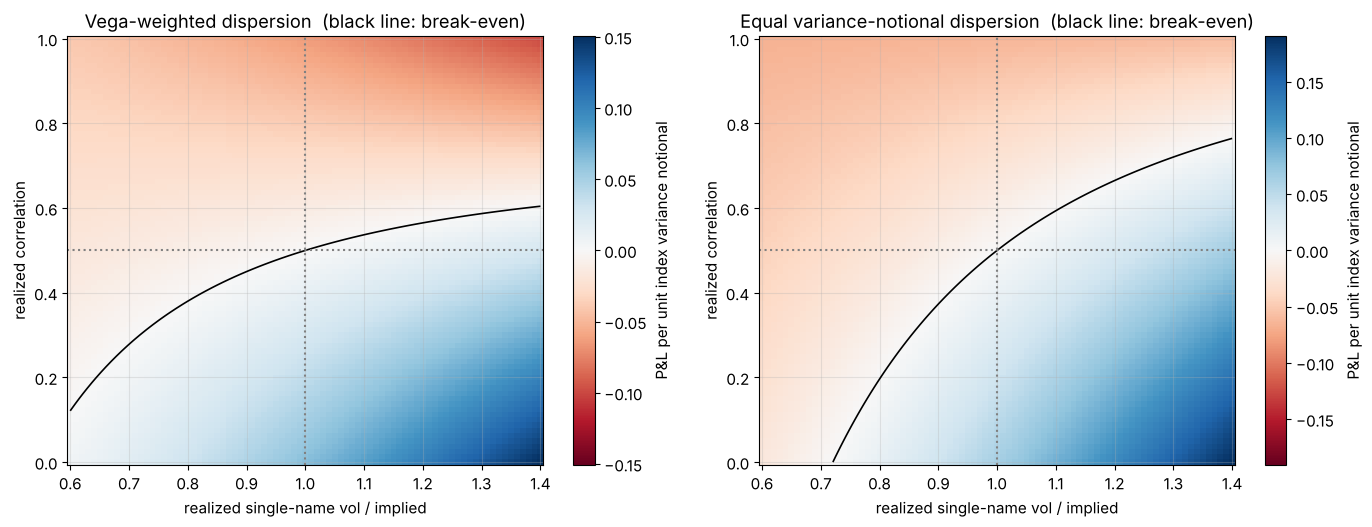

Left: horizontal contours -- the vega-weighted trade is a correlation bet and nearly nothing else.
Right: tilted contours -- the equal-notional trade also pays off when all vols rise. Different trade, same name.


In [17]:
rng = np.random.default_rng(13)
n_stk = 10
w = np.full(n_stk, 1 / n_stk)
sig_imp = rng.uniform(0.25, 0.45, n_stk)          # single-name implied vols
rho_imp = 0.50                                     # the correlation the index option market implies

def index_var(sig, rho, w):
    C = np.full((len(sig), len(sig)), rho); np.fill_diagonal(C, 1.0)
    Sig = np.outer(sig, sig) * C
    return float(w @ Sig @ w)

def implied_corr(sig_I, sig, w):
    own = np.sum(w**2 * sig**2)
    cross = np.sum(np.outer(w * sig, w * sig)) - own
    return (sig_I**2 - own) / cross

sig_I_imp = np.sqrt(index_var(sig_imp, rho_imp, w))
rho_back = implied_corr(sig_I_imp, sig_imp, w)
assert abs(rho_back - rho_imp) < 1e-12
print(f"Index implied vol from components at rho={rho_imp}: {sig_I_imp:.4f};  implied correlation recovered: {rho_back:.4f}")

# Variance-swap implementation of dispersion. Var notional N; P&L = N (realized var - strike var).
N_I = 1.0                                              # short 1 unit of index variance notional
N_vega  = w * sig_I_imp * N_I / sig_imp                # vega-weighted: each name's vega notional 2 sigma_i N_i = w_i * 2 sigma_I N_I
N_equal = w * N_I                                      # equal variance-notional

def dispersion_pnl(mult, rho_real, N_single):
    sig_real = sig_imp * mult                          # common multiplier on realized single-name vol
    pnl_single = np.sum(N_single * (sig_real**2 - sig_imp**2))
    pnl_index = -N_I * (index_var(sig_real, rho_real, w) - sig_I_imp**2)
    return pnl_single + pnl_index

assert abs(dispersion_pnl(1.0, rho_imp, N_vega)) < 1e-12 and abs(dispersion_pnl(1.0, rho_imp, N_equal)) < 1e-12

mults = np.linspace(0.6, 1.4, 81); rhos = np.linspace(0.0, 1.0, 81)
MM, RR = np.meshgrid(mults, rhos)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for ax, N_single, title in [(axes[0], N_vega, "Vega-weighted dispersion"), (axes[1], N_equal, "Equal variance-notional dispersion")]:
    P = np.vectorize(lambda m_, r_: dispersion_pnl(m_, r_, N_single))(MM, RR)
    lim = np.abs(P).max()
    im = ax.pcolormesh(MM, RR, P, cmap="RdBu", norm=TwoSlopeNorm(0, -lim, lim), shading="auto")
    ax.contour(MM, RR, P, levels=[0], colors="k", linewidths=1.2)
    ax.axhline(rho_imp, color="gray", ls=":"); ax.axvline(1.0, color="gray", ls=":")
    ax.set_xlabel("realized single-name vol / implied"); ax.set_ylabel("realized correlation")
    ax.set_title(title + "  (black line: break-even)")
    fig.colorbar(im, ax=ax, label="P&L per unit index variance notional")
plt.tight_layout(); plt.show()
print("Left: horizontal contours -- the vega-weighted trade is a correlation bet and nearly nothing else.")
print("Right: tilted contours -- the equal-notional trade also pays off when all vols rise. Different trade, same name.")

### 8b. Financing hidden in the chain: boxes, conversions and the borrow

**Sources:** van Binsbergen, Diamond & Grotteria (2022), *Risk-Free Interest Rates*, JFE
(extracting the risk-free curve from SPX box spreads); Ofek, Richardson & Whitelaw (2004),
*Limited Arbitrage and Short Sales Restrictions*, JFE (put-call parity violations and the
borrow); Jane Street and Susquehanna are frequently cited as large participants in the SPX
box market, where boxes trade as a funding instrument.

Put-call parity with a stock-borrow fee $b$:

$$
C - P = S e^{-(q+b)T} - K e^{-rT}
\quad\Longrightarrow\quad
F_{\text{imp}} = (C - P)e^{rT} + K, \qquad b_{\text{imp}} = r - q - \frac{1}{T}\ln\frac{F_{\text{imp}}}{S}
$$

Every strike pair is an independent noisy estimate of the same forward, so the chain reveals
the market's borrow rate — and a market maker who prices off the wrong forward shows a
symptom: calls and puts at the same strike imply *different* volatilities ("put-call vol
spread"). A **box** (long call spread + long put spread, same strikes) is a riskless zero-coupon
bond paying $K_2 - K_1$ at expiry, so its price implies a financing rate:

$$
r_{\text{box}} = -\frac{1}{T}\ln\frac{\text{Box}}{K_2 - K_1}
$$

Its precision scales as $1/(T(K_2-K_1))$ — which is why the financing trade lives in wide,
long-dated SPX boxes and not in weekly single-stock options.

True borrow 3.00%; chain-implied borrow mean 3.0022% (std across strikes 0.0117%)
Strikes where a no-borrow call IV does not even exist (price below the no-borrow bound): 5 of 25


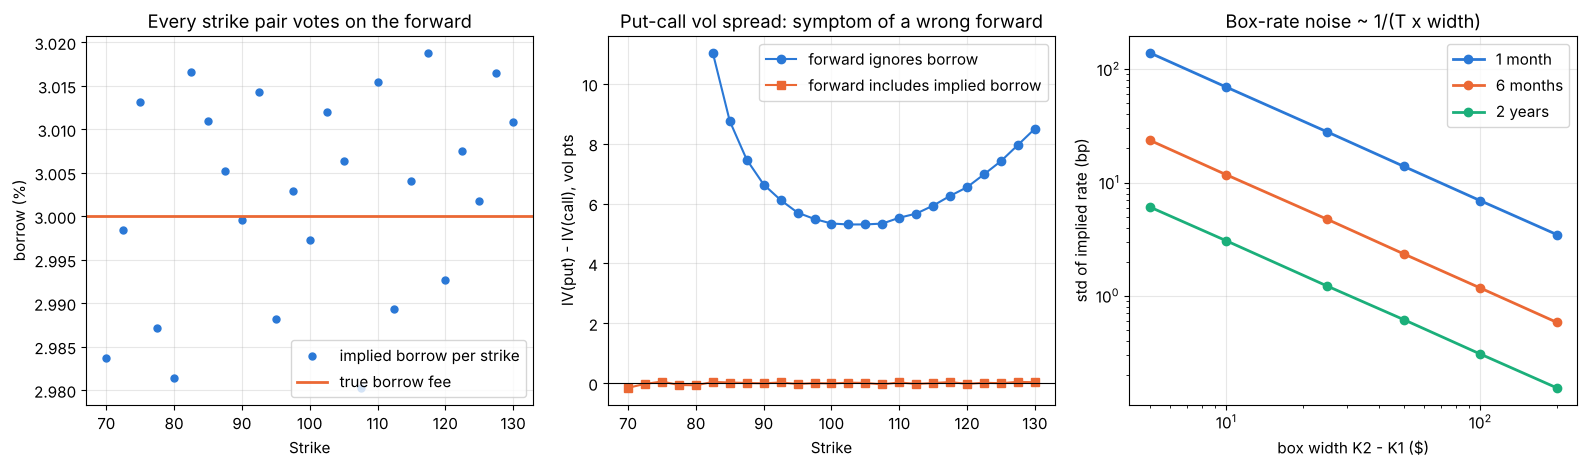

In [18]:
rng = np.random.default_rng(14)
b_true, T_b, sig_b = 0.03, 0.5, 0.30           # a 3% borrow fee, six months, 30% vol
Ks = np.arange(70, 131, 2.5)
C_true = bs_price(S0, Ks, T_b, r, q + b_true, sig_b, "call")
P_true = bs_price(S0, Ks, T_b, r, q + b_true, sig_b, "put")
C_obs = np.round(C_true + rng.uniform(-0.005, 0.005, Ks.size), 2)   # observed mids, rounded to the cent
P_obs = np.round(P_true + rng.uniform(-0.005, 0.005, Ks.size), 2)

F_imp = (C_obs - P_obs) * np.exp(r * T_b) + Ks
b_imp = r - q - np.log(F_imp / S0) / T_b
print(f"True borrow {b_true:.2%}; chain-implied borrow mean {b_imp.mean():.4%} (std across strikes {b_imp.std():.4%})")
assert abs(b_imp.mean() - b_true) < 0.003

# The symptom when the desk ignores the borrow: invert IVs using q only.
# Deep ITM calls priced WITH the borrow sit below the no-borrow lower bound, so there is no IV at all there -- that is itself the tell.
def safe_iv(price, K, yld, kind):
    try:
        return implied_vol(price, S0, K, T_b, r, yld, kind)
    except ValueError:
        return np.nan
iv_c = np.array([safe_iv(c, K, q, "call") for c, K in zip(C_obs, Ks)])
iv_p = np.array([safe_iv(p, K, q, "put") for p, K in zip(P_obs, Ks)])
iv_c_ok = np.array([safe_iv(c, K, q + b_imp.mean(), "call") for c, K in zip(C_obs, Ks)])
iv_p_ok = np.array([safe_iv(p, K, q + b_imp.mean(), "put") for p, K in zip(P_obs, Ks)])
print(f"Strikes where a no-borrow call IV does not even exist (price below the no-borrow bound): {int(np.isnan(iv_c).sum())} of {Ks.size}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].plot(Ks, b_imp * 100, "o", ms=5, label="implied borrow per strike")
axes[0].axhline(b_true * 100, color=PALETTE[1], lw=2, label="true borrow fee")
axes[0].set_xlabel("Strike"); axes[0].set_ylabel("borrow (%)"); axes[0].set_title("Every strike pair votes on the forward"); axes[0].legend()
axes[1].plot(Ks, (iv_p - iv_c) * 100, "o-", lw=1.5, label="forward ignores borrow")
axes[1].plot(Ks, (iv_p_ok - iv_c_ok) * 100, "s-", lw=1.5, label="forward includes implied borrow")
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_xlabel("Strike"); axes[1].set_ylabel("IV(put) - IV(call), vol pts")
axes[1].set_title("Put-call vol spread: symptom of a wrong forward"); axes[1].legend()

# Box precision vs width and tenor, with 1-cent rounding noise on each of the four legs
def box_rate_std(width, T, n=20000):
    noise = rng.uniform(-0.005, 0.005, (n, 4)).sum(axis=1)        # four legs rounded independently
    box = width * np.exp(-r * T) + noise
    return np.std(-np.log(box / width) / T)
widths = np.array([5, 10, 25, 50, 100, 200])
for T_box, lab in [(1 / 12, "1 month"), (0.5, "6 months"), (2.0, "2 years")]:
    axes[2].loglog(widths, [box_rate_std(wd, T_box) * 1e4 for wd in widths], "o-", lw=2, label=lab)
axes[2].set_xlabel("box width K2 - K1 ($)"); axes[2].set_ylabel("std of implied rate (bp)")
axes[2].set_title("Box-rate noise ~ 1/(T x width)"); axes[2].legend()
plt.tight_layout(); plt.show()

### 8c. Event volatility: pricing the earnings jump

**Sources:** Dubinsky, Johannes, Kaeck & Seeger (2019), *Option Pricing of Earnings
Announcement Risks*, RFS; Patell & Wolfson (1979, 1981) for the original observation that
implied vol rises into earnings and collapses after; Brenner & Subrahmanyam (1988) for the
straddle approximation.

If a scheduled announcement at time $t_E$ adds a jump with variance $\sigma_J^2$ on top of
diffusive variance $\sigma_d^2$ per year, total implied variance is additive:

$$
\sigma_{\text{imp}}^2(T)\,T = \sigma_d^2\,T + \sigma_J^2\,\mathbf 1_{\{T \ge t_E\}}
\quad\Longrightarrow\quad
\sigma_{\text{imp}}(T) = \sqrt{\sigma_d^2 + \sigma_J^2 / T}
$$

The term structure shows a *kink* at the event and decays as $T^{-1/2}$ afterwards — the
shape a desk uses to read $\sigma_J$ straight off the screen. The ATM straddle expiring just
after the event prices the expected absolute move; Brenner-Subrahmanyam gives
$\text{Straddle}_{ATM} \approx \sqrt{2/\pi}\,\sigma\sqrt T\,S \approx 0.8\,\sigma\sqrt T\,S$.

The event trade is then a comparison between the implied $\sigma_J$ and the distribution of
the name's *historical* announcement moves — which is fat-tailed, so the comparison is
between a market price and a quantity whose sample mean is a bad estimator. The market
maker who sells event vol collects most quarters and pays out large on a few.

ATM-forward straddle 5.6888 vs Brenner-Subrahmanyam 0.8 sigma sqrt(T) S = 5.6914 (-0.04%)
Implied one-sigma earnings move: 6.0% -> expected absolute move ~ 4.79% of spot


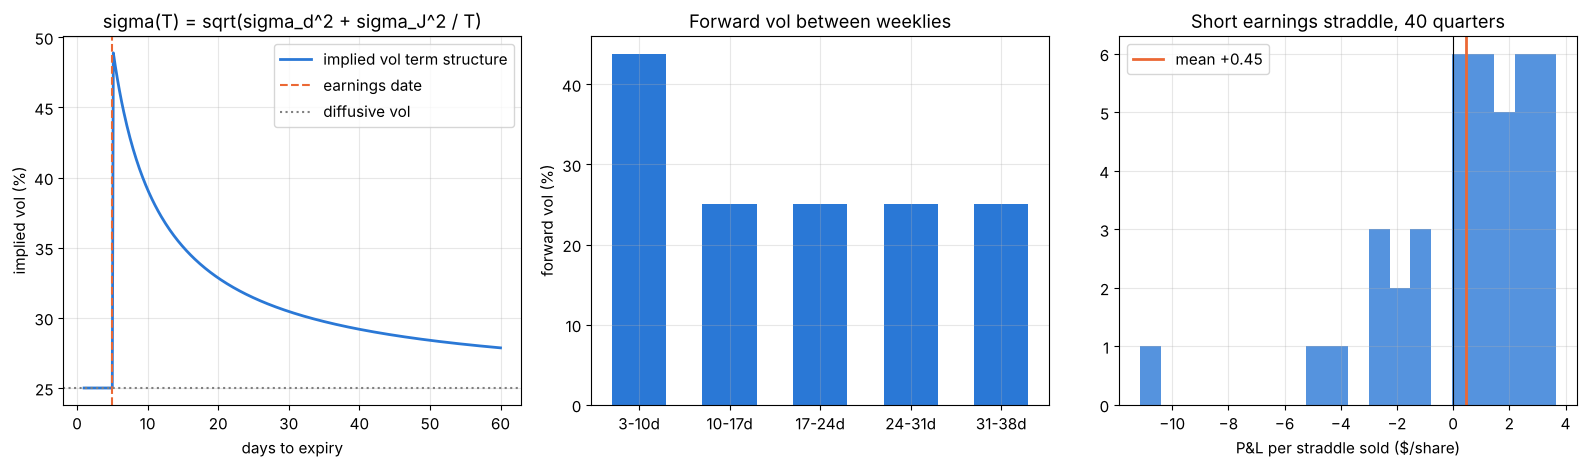

Win rate 72%, worst quarter -11.15, skew -2.03. The premium is real; so is the tail.


In [19]:
sig_d, sig_J = 0.25, 0.06                 # 25% diffusive vol, 6% one-sigma earnings move
t_E = 5 * DAY
Ts = np.linspace(1 * DAY, 60 * DAY, 400)
iv_term = np.sqrt(sig_d**2 + np.where(Ts >= t_E, sig_J**2 / Ts, 0.0))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].plot(Ts / DAY, iv_term * 100, lw=2, label="implied vol term structure")
axes[0].axvline(t_E / DAY, color=PALETTE[1], ls="--", label="earnings date")
axes[0].axhline(sig_d * 100, color="gray", ls=":", label="diffusive vol")
axes[0].set_xlabel("days to expiry"); axes[0].set_ylabel("implied vol (%)"); axes[0].set_title("sigma(T) = sqrt(sigma_d^2 + sigma_J^2 / T)"); axes[0].legend()

# forward vol between adjacent weekly expiries
weeklies = np.array([3, 10, 17, 24, 31, 38]) * DAY
w_tot = (sig_d**2 * weeklies + np.where(weeklies >= t_E, sig_J**2, 0.0))
fwd_var = np.diff(w_tot) / np.diff(weeklies)
axes[1].bar(np.arange(len(fwd_var)), np.sqrt(fwd_var) * 100, color=PALETTE[0], width=0.6)
axes[1].set_xticks(np.arange(len(fwd_var))); axes[1].set_xticklabels([f"{int(a/DAY)}-{int(b/DAY)}d" for a, b in zip(weeklies[:-1], weeklies[1:])])
axes[1].set_ylabel("forward vol (%)"); axes[1].set_title("Forward vol between weeklies")

# Brenner-Subrahmanyam check and the earnings-straddle P&L distribution
T_ev = 6 * DAY
iv_ev = np.sqrt(sig_d**2 + sig_J**2 / T_ev)
K_atm = S0 * np.exp((r - q) * T_ev)
straddle = bs_price(S0, K_atm, T_ev, r, q, iv_ev, "call") + bs_price(S0, K_atm, T_ev, r, q, iv_ev, "put")
bs_approx = np.sqrt(2 / np.pi) * iv_ev * np.sqrt(T_ev) * S0
print(f"ATM-forward straddle {straddle:.4f} vs Brenner-Subrahmanyam 0.8 sigma sqrt(T) S = {bs_approx:.4f} ({(straddle/bs_approx-1):+.2%})")
assert abs(straddle / bs_approx - 1) < 0.01
print(f"Implied one-sigma earnings move: {sig_J:.1%} -> expected absolute move ~ {np.sqrt(2/np.pi)*sig_J:.2%} of spot")

rng = np.random.default_rng(15)
n_q = 40                                                        # ten years of quarters
hist_moves = student_t.rvs(df=3, size=n_q, random_state=rng) * 0.05 / np.sqrt(3)   # fat-tailed, 5% std
event_pnl = straddle - np.abs(hist_moves) * S0 - 0.6 * sig_d * np.sqrt(T_ev) * S0 * 0.8   # minus the diffusive part the hedger pays over 6 days (approx)
axes[2].hist(event_pnl, bins=20, color=PALETTE[0], alpha=0.8)
axes[2].axvline(0, color="k", lw=0.8); axes[2].axvline(event_pnl.mean(), color=PALETTE[1], lw=2, label=f"mean {event_pnl.mean():+.2f}")
axes[2].set_xlabel("P&L per straddle sold ($/share)"); axes[2].set_title(f"Short earnings straddle, {n_q} quarters"); axes[2].legend()
plt.tight_layout(); plt.show()
print(f"Win rate {np.mean(event_pnl>0):.0%}, worst quarter {event_pnl.min():.2f}, skew {pd.Series(event_pnl).skew():.2f}. The premium is real; so is the tail.")

### 8d. Expiry day: gamma, theta, pin risk and 0DTE

As $T \to 0$ the ATM gamma $\Gamma = \varphi(d_1)/(S\sigma\sqrt T)$ diverges and the
theta that pays for it diverges with it. The market maker short an ATM option on expiry day
is running the Section 5 identity at its most violent: enormous gamma, hedge intervals that
are a large fraction of the remaining life, and a delta that flips from 0 to 1 across a few
ticks (**pin risk**: at the close, you do not know whether you will be assigned, so you do
not know your delta). Since Cboe moved SPX to daily expiries, same-day options have been
roughly half of SPX volume; Optiver, Citadel Securities and SIG are among the firms publicly
associated with quoting that complex.

The hedging error of a discretely hedged short straddle, as a fraction of its premium, grows
like $\sqrt{\delta t / T}$ as expiry approaches with a fixed rebalancing interval — the same
$1/\sqrt N$ law as Section 5, with $N = T/\delta t$ shrinking. We verify that slope.

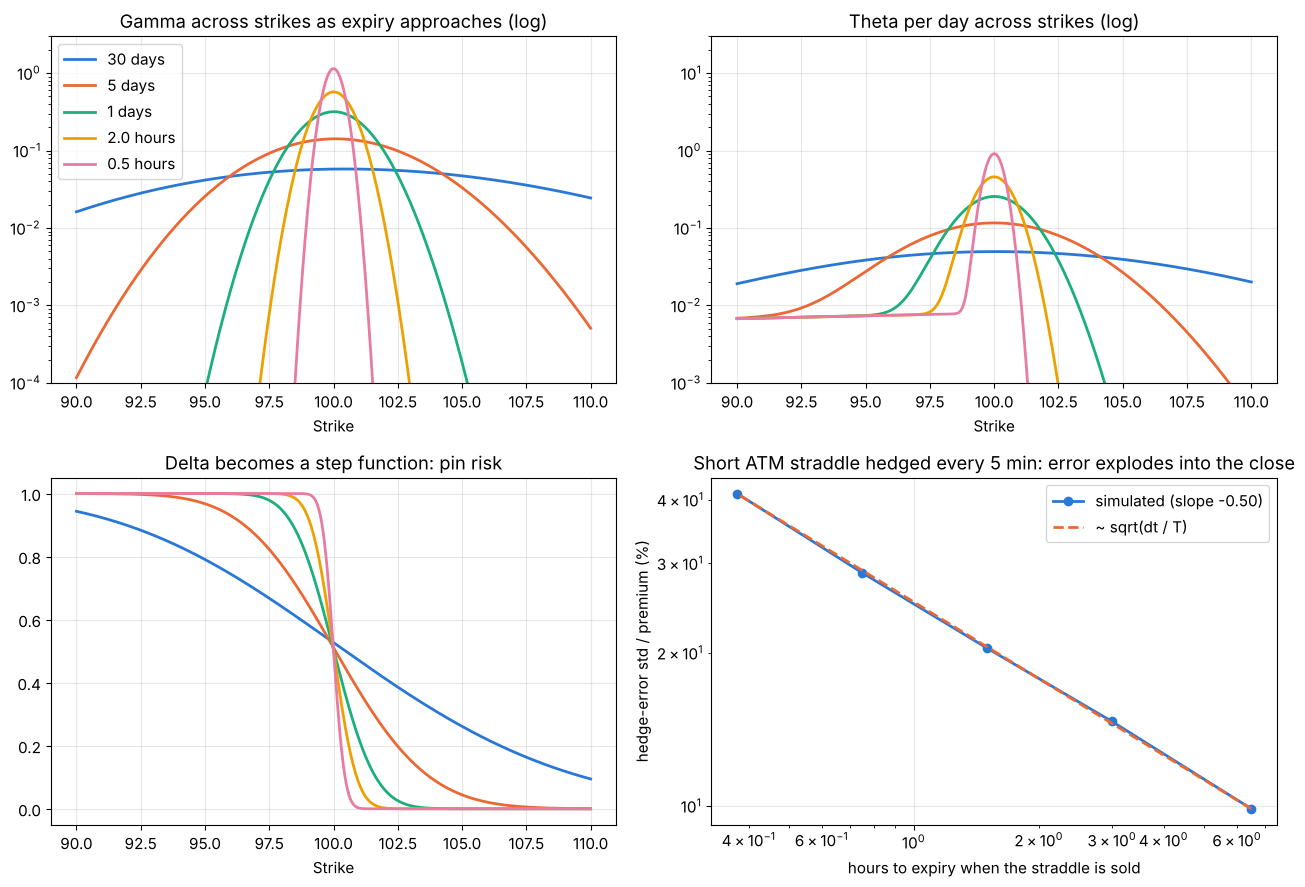

Hedge error as a fraction of premium: 10% with a full day left, 41% with 22 minutes left.
A 0DTE market maker is not earning theta; they are earning the spread on an enormous volume of gamma they cannot hedge.


In [20]:
hours = np.array([30 * 6.5, 5 * 6.5, 6.5, 2.0, 0.5])      # 30 days, 5 days, 1 day, 2 hours, 30 minutes to expiry
HOUR = DAY / 6.5
Ks = np.linspace(90, 110, 401)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for h, col in zip(hours, PALETTE):
    T = h * HOUR
    g = bs_greeks(S0, Ks, T, r, q, 0.20, "call")
    lab = f"{h/6.5:.0f} days" if h >= 6.5 else f"{h:.1f} hours"
    axes[0, 0].semilogy(Ks, g["gamma"], lw=2, color=col, label=lab)
    axes[0, 1].semilogy(Ks, -g["theta"] * DAY, lw=2, color=col, label=lab)
    axes[1, 0].plot(Ks, g["delta"], lw=2, color=col, label=lab)
axes[0, 0].set_title("Gamma across strikes as expiry approaches (log)"); axes[0, 0].legend(); axes[0, 0].set_xlabel("Strike"); axes[0, 0].set_ylim(1e-4, 3)
axes[0, 1].set_title("Theta per day across strikes (log)"); axes[0, 1].set_xlabel("Strike"); axes[0, 1].set_ylim(1e-3, 30)
axes[1, 0].set_title("Delta becomes a step function: pin risk"); axes[1, 0].set_xlabel("Strike")

# hedge error of a short ATM straddle hedged every 5 minutes over the final H hours
rng = np.random.default_rng(16)
dt_rebal = 5 / 60 * HOUR
hours_grid = np.array([6.5, 3.0, 1.5, 0.75, 0.375])
rel_err = []
for H in hours_grid:
    T = H * HOUR
    N = int(round(T / dt_rebal))
    tt = np.linspace(0, T, N + 1)
    paths = gbm_paths(3000, N, T, 0.20, rng)
    oc = hedge_short_option_on_paths(paths, tt, 100.0, T, 0.20, "call")
    op = hedge_short_option_on_paths(paths, tt, 100.0, T, 0.20, "put")
    pnl = oc["pnl"] + op["pnl"]
    rel_err.append(pnl.std() / (oc["premium"] + op["premium"]))
rel_err = np.array(rel_err)
slope = np.polyfit(np.log(hours_grid), np.log(rel_err), 1)[0]
axes[1, 1].loglog(hours_grid, rel_err * 100, "o-", lw=2, label=f"simulated (slope {slope:.2f})")
axes[1, 1].loglog(hours_grid, rel_err[0] * 100 * np.sqrt(hours_grid[0] / hours_grid), "--", lw=2, label="~ sqrt(dt / T)")
axes[1, 1].set_xlabel("hours to expiry when the straddle is sold"); axes[1, 1].set_ylabel("hedge-error std / premium (%)")
axes[1, 1].set_title("Short ATM straddle hedged every 5 min: error explodes into the close"); axes[1, 1].legend()
plt.tight_layout(); plt.show()
assert -0.7 < slope < -0.3, slope
print(f"Hedge error as a fraction of premium: {rel_err[0]:.0%} with a full day left, {rel_err[-1]:.0%} with 22 minutes left.")
print("A 0DTE market maker is not earning theta; they are earning the spread on an enormous volume of gamma they cannot hedge.")

### 8e. The variance risk premium: why the market maker is structurally short vol

**Sources:** Bakshi & Kapadia (2003), *Delta-Hedged Gains and the Negative Market Volatility
Risk Premium*, RFS; Carr & Wu (2009), *Variance Risk Premia*, RFS; Bollerslev, Tauchen &
Zhou (2009).

Customers in aggregate buy protection, so the market-making community in aggregate is short
options. That inventory is paid for: implied vol exceeds subsequently realized vol on average
(the variance risk premium, VRP), so a short, delta-hedged position earns the Section 5
integral on average. The distribution is the catch — small steady gains and occasional
severe losses when realized variance spikes. We generate it from Heston under two measures:
the physical $\mathbb P$ with a lower long-run variance $\theta_{\mathbb P}$, and the pricing
measure $\mathbb Q$ with $\theta_{\mathbb Q} > \theta_{\mathbb P}$. The one-month ATM implied
variance is approximated by the $\mathbb Q$ variance-swap rate
$\theta_{\mathbb Q} + (v_0 - \theta_{\mathbb Q})\frac{1-e^{-\kappa T}}{\kappa T}$ — checked
against the actual Heston implied vol before use.

1-month ATM implied vol: Heston 0.1738  vs  variance-swap proxy 0.1781  (diff 0.43 vol pts)


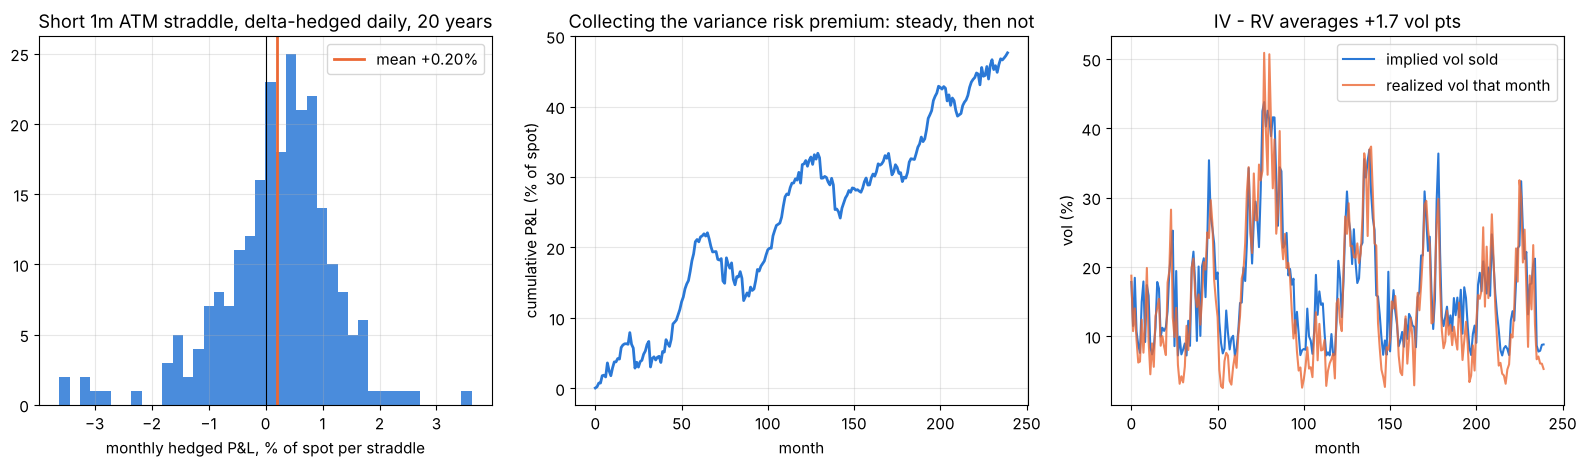

Mean +0.198%  std 1.011%  skew -0.83  worst month -3.62%  win rate 66%
Negative skew is the fee the market maker is paid for warehousing the inventory nobody else wants. Section 9 is about surviving it.


In [21]:
kappa_v, xi_v, rho_v = 3.0, 0.5, -0.7
theta_P, theta_Q = 0.030, 0.045          # ~17% realized long-run vol priced as ~21%
T_m = 21 * DAY

def q_var_swap(v0, T, theta=theta_Q, kappa=kappa_v):
    return theta + (v0 - theta) * (1 - np.exp(-kappa * T)) / (kappa * T)

# Validate the proxy: Heston ATM implied vol vs. sqrt(variance-swap rate) at a reference state
v_ref = theta_P
K_ref = S0 * np.exp((r - q) * T_m)
iv_heston = implied_vol(heston_call(S0, K_ref, T_m, r, q, kappa_v, theta_Q, xi_v, rho_v, v_ref), S0, K_ref, T_m, r, q)
iv_proxy = np.sqrt(q_var_swap(v_ref, T_m))
print(f"1-month ATM implied vol: Heston {iv_heston:.4f}  vs  variance-swap proxy {iv_proxy:.4f}  (diff {abs(iv_heston-iv_proxy)*100:.2f} vol pts)")
assert abs(iv_heston - iv_proxy) < 0.01

# 240 months of P-dynamics, daily steps; each month sell the ATM straddle at the proxy IV and delta-hedge daily.
rng = np.random.default_rng(17)
n_months, n_days = 240, 21
S, v = S0, theta_P
monthly_pnl, iv_sold, rv_real = [], [], []
dt = DAY
for mth in range(n_months):
    Z1 = rng.standard_normal(n_days); Z2 = rho_v * Z1 + np.sqrt(1 - rho_v**2) * rng.standard_normal(n_days)
    path = np.empty(n_days + 1); path[0] = S
    vs = np.empty(n_days + 1); vs[0] = v
    for d in range(n_days):
        vp = max(vs[d], 0.0)
        path[d + 1] = path[d] * np.exp((0.05 - 0.5 * vp) * dt + np.sqrt(vp * dt) * Z1[d])
        vs[d + 1] = vs[d] + kappa_v * (theta_P - vp) * dt + xi_v * np.sqrt(vp * dt) * Z2[d]
    sig_sold = np.sqrt(q_var_swap(max(v, 1e-6), T_m))
    K = path[0] * np.exp((r - q) * T_m)
    tt = np.linspace(0, T_m, n_days + 1)
    oc = hedge_short_option_on_paths(path[None, :], tt, K, T_m, sig_sold, "call")
    op = hedge_short_option_on_paths(path[None, :], tt, K, T_m, sig_sold, "put")
    monthly_pnl.append(float(oc["pnl"][0] + op["pnl"][0]) / path[0] * 100)     # in % of spot, per straddle
    iv_sold.append(sig_sold); rv_real.append(np.std(np.diff(np.log(path))) * np.sqrt(252))
    S, v = path[-1], vs[-1]
monthly_pnl, iv_sold, rv_real = map(np.array, (monthly_pnl, iv_sold, rv_real))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].hist(monthly_pnl, bins=40, color=PALETTE[0], alpha=0.85)
axes[0].axvline(0, color="k", lw=0.8); axes[0].axvline(monthly_pnl.mean(), color=PALETTE[1], lw=2, label=f"mean {monthly_pnl.mean():+.2f}%")
axes[0].set_xlabel("monthly hedged P&L, % of spot per straddle"); axes[0].set_title("Short 1m ATM straddle, delta-hedged daily, 20 years"); axes[0].legend()
axes[1].plot(np.cumsum(monthly_pnl), lw=2)
axes[1].set_xlabel("month"); axes[1].set_ylabel("cumulative P&L (% of spot)"); axes[1].set_title("Collecting the variance risk premium: steady, then not")
axes[2].plot(iv_sold * 100, lw=1.5, label="implied vol sold")
axes[2].plot(rv_real * 100, lw=1.5, alpha=0.8, label="realized vol that month")
axes[2].set_xlabel("month"); axes[2].set_ylabel("vol (%)"); axes[2].set_title(f"IV - RV averages {np.mean(iv_sold-rv_real)*100:+.1f} vol pts"); axes[2].legend()
plt.tight_layout(); plt.show()
s = pd.Series(monthly_pnl)
print(f"Mean {s.mean():+.3f}%  std {s.std():.3f}%  skew {s.skew():+.2f}  worst month {s.min():+.2f}%  win rate {np.mean(monthly_pnl>0):.0%}")
print("Negative skew is the fee the market maker is paid for warehousing the inventory nobody else wants. Section 9 is about surviving it.")

## 9. Risk management: the spot/vol grid, Greek ladders, and how inventory skews the quotes

**Sources:** Gârleanu, Pedersen & Poteshman (2009), *Demand-Based Option Pricing*, RFS — the
paper that shows market-maker inventory *bends the surface*; Ho & Stoll (1981) for inventory
pricing; Stoikov & Sağlam (2009), *Option Market Making under Inventory Risk*; Baldacci,
Bergault & Guéant (2021), *Algorithmic Market Making for Options*, Quantitative Finance;
Muravyev (2016), *Order Flow and Expected Option Returns*, J. Finance, for the empirical
inventory-pressure evidence.

A book is a position vector across (strike, expiry, call/put). The desk looks at it three ways:

1. **The spot/vol P&L grid.** Reprice the entire book on a grid of spot and vol shocks. This
   is the single most-used risk report on any options desk because it is model-light: it
   shows the *shape* of the exposure including everything the Greeks are a Taylor expansion of.
2. **Greek ladders.** Vega bucketed by expiry, gamma bucketed by strike — because hedges are
   bucket-specific (you cannot hedge 3-month vega with a 1-week option).
3. **The Taylor approximation and its residual.**
   $\delta P \approx \Delta\,\delta S + \tfrac12\Gamma\,\delta S^2 + \mathcal V\,\delta\sigma
   + \text{Vanna}\,\delta S\,\delta\sigma + \tfrac12\text{Volga}\,\delta\sigma^2$.
   Plotting the residual (full repricing minus Taylor) shows exactly where "managing the Greeks" stops being enough.

### Inventory skew: the book bends the surface

Give the desk a quadratic penalty on its risk-factor exposures $G$ (vega, gamma-dollars),
$\;U = -\tfrac{\gamma}{2}\,G^\top\Lambda G$. The marginal cost of adding one unit of option
$i$ with exposures $g_i$ is $\gamma\, g_i^\top\Lambda G$, so the **reservation price** is the
theo minus that cost, and in vol units the quote shifts by

$$
\delta\sigma_i \;=\; -\,\frac{\gamma\, g_i^\top \Lambda\, G}{\mathcal V_i}
$$

A book that is short vega has $G_{\mathcal V}<0$, so $\delta\sigma_i > 0$: every quote moves up,
most in the buckets where the book is shortest. This is the mechanism by which customer demand
for puts becomes a steeper skew — not a belief about crashes, but inventory.

In [22]:
# --- A book that looks like a real one: customers bought downside puts and sold upside calls, the desk is the other side. ---
rng = np.random.default_rng(18)
book_strikes = np.arange(80, 121, 5.0)
book_expiries = np.array([15, 45, 90]) * DAY
beta_skew = -0.3
def surface_vol(K, T, S=S0, base=0.22):
    return np.clip(base + beta_skew * np.log(K / S) / np.sqrt(T / (45 * DAY)), 0.10, 1.5)

instr = []
for T in book_expiries:
    for K in book_strikes:
        for kind in ("call", "put"):
            # customers buy OTM puts (desk short), sell OTM calls (desk long), with random lumps
            if kind == "put":
                pos = -rng.integers(50, 400) if K <= 100 else rng.integers(-100, 100)
            else:
                pos = rng.integers(50, 300) if K >= 100 else rng.integers(-100, 100)
            instr.append((K, T, kind, int(pos)))
book = pd.DataFrame(instr, columns=["K", "T", "kind", "pos"])
book["sigma"] = surface_vol(book["K"].values, book["T"].values)

def book_value(S, dsig, T_shift=0.0):
    tot = np.zeros(np.shape(S)) if np.ndim(S) else 0.0
    for kind in ("call", "put"):
        b = book[book.kind == kind]
        for K, T, pos, sig in zip(b.K, b["T"], b.pos, b.sigma):
            tot = tot + pos * bs_price(S, K, T - T_shift, r, q, np.maximum(sig + dsig, 0.02), kind)
    return tot

def book_greeks(S=S0, dsig=0.0):
    tot = {k: 0.0 for k in ("delta", "gamma", "vega", "theta", "vanna", "volga")}
    for kind in ("call", "put"):
        b = book[book.kind == kind]
        g = bs_greeks(S, b.K.values, b["T"].values, r, q, np.maximum(b.sigma.values + dsig, 0.02), kind)
        for k in tot:
            tot[k] += float(np.sum(b.pos.values * g[k]))
    return tot

G0 = book_greeks()
print("Book Greeks (per share units):", {k: round(float(v), 1) for k, v in G0.items()})
print(f"Net position: {book.pos.sum()} contracts; short vega {G0['vega']:.0f} means ${G0['vega']*100*0.01:,.0f} per vol point on a 100-multiplier.")

Book Greeks (per share units): {'delta': 1718.4, 'gamma': -8.8, 'vega': -8023.8, 'theta': 3553.0, 'vanna': 3120.4, 'volga': 6674.0}
Net position: -330 contracts; short vega -8024 means $-8,024 per vol point on a 100-multiplier.


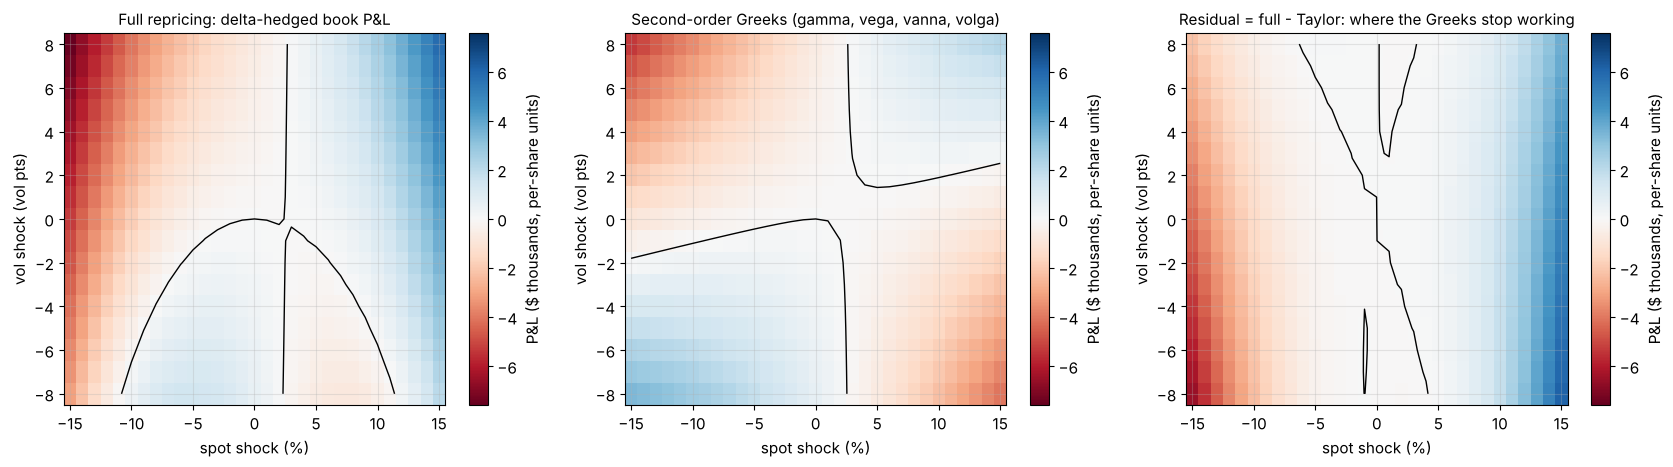

Worst cell on the grid: -7.6k at spot -15%, vol +8 pts.
Taylor residual / worst P&L in the region:  +/-2% spot, +/-1.5 vol pts: 9%  |  +/-5%, +/-3 pts: 27%  |  whole grid: 86%
With 15-day options on the book, second-order Greeks stop being a good description well inside a 5% move (speed, colour and
the vanna/volga of the short-dated wing take over). Greeks are a day-to-day tool; for a crash scenario you reprice, you do not expand.


In [23]:
# --- The spot/vol grid, its Taylor approximation, and the residual ---
spot_shocks = np.linspace(-0.15, 0.15, 31)
vol_shocks = np.linspace(-0.08, 0.08, 17)
SS, VV = np.meshgrid(spot_shocks, vol_shocks)
base_val = book_value(S0, 0.0)
# delta-hedge the book first, as the desk would, so the grid shows the option risk and not the stock
hedge_shares = -G0["delta"]
full = np.vectorize(lambda s, dv: book_value(S0 * (1 + s), dv) + hedge_shares * S0 * (1 + s) - base_val - hedge_shares * S0)(SS, VV)
dS = SS * S0
taylor = (0.5 * G0["gamma"] * dS**2 + G0["vega"] * VV + G0["vanna"] * dS * VV + 0.5 * G0["volga"] * VV**2)
resid = full - taylor

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
lim = np.abs(full).max()
for ax, Z, title in [(axes[0], full, "Full repricing: delta-hedged book P&L"),
                     (axes[1], taylor, "Second-order Greeks (gamma, vega, vanna, volga)"),
                     (axes[2], resid, "Residual = full - Taylor: where the Greeks stop working")]:
    im = ax.pcolormesh(SS * 100, VV * 100, Z / 1000, cmap="RdBu", norm=TwoSlopeNorm(0, -lim / 1000, lim / 1000), shading="auto")
    ax.contour(SS * 100, VV * 100, Z, levels=[0], colors="k", linewidths=1)
    ax.set_xlabel("spot shock (%)"); ax.set_ylabel("vol shock (vol pts)"); ax.set_title(title, fontsize=11)
    fig.colorbar(im, ax=ax, label="P&L ($ thousands, per-share units)")
plt.tight_layout(); plt.show()
print(f"Worst cell on the grid: {full.min()/1000:,.1f}k at spot {SS.ravel()[full.argmin()]:+.0%}, vol {VV.ravel()[full.argmin()]*100:+.0f} pts.")
def resid_ratio(ds_max, dv_max):
    m = (np.abs(SS) <= ds_max + 1e-9) & (np.abs(VV) <= dv_max + 1e-9)
    return np.abs(resid[m]).max() / np.abs(full[m]).max()
ratio_tight, ratio_inner, ratio_full = resid_ratio(0.02, 0.015), resid_ratio(0.05, 0.03), resid_ratio(1.0, 1.0)
print(f"Taylor residual / worst P&L in the region:  +/-2% spot, +/-1.5 vol pts: {ratio_tight:.0%}  |  +/-5%, +/-3 pts: {ratio_inner:.0%}  |  whole grid: {ratio_full:.0%}")
print("With 15-day options on the book, second-order Greeks stop being a good description well inside a 5% move (speed, colour and")
print("the vanna/volga of the short-dated wing take over). Greeks are a day-to-day tool; for a crash scenario you reprice, you do not expand.")
assert ratio_tight < 0.10, ratio_tight

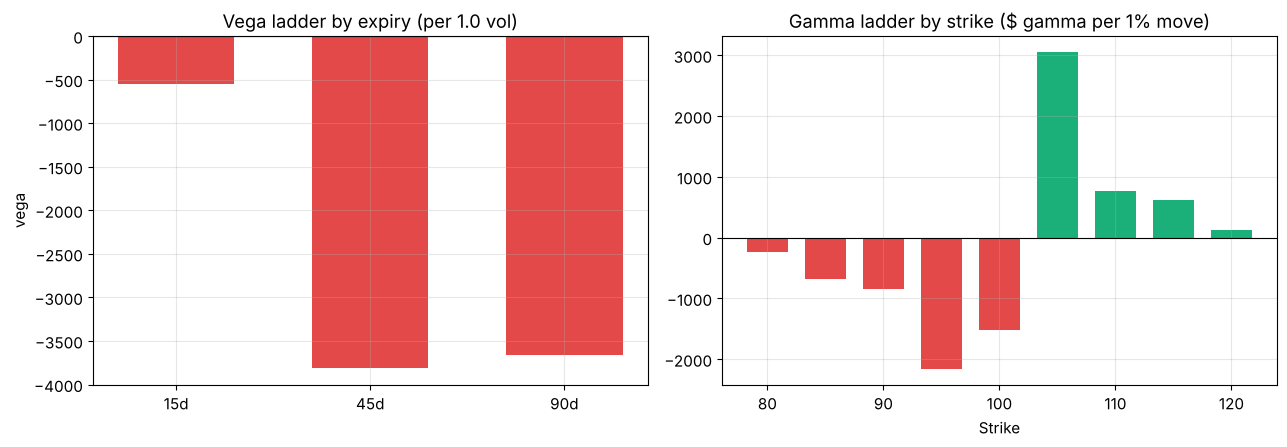

Short the downside gamma, long the upside gamma, short vega in every bucket: the classic 'customers bought puts and sold calls' book.


In [24]:
# --- Greek ladders: vega by expiry, gamma by strike ---
lad = []
for kind in ("call", "put"):
    b = book[book.kind == kind]
    g = bs_greeks(S0, b.K.values, b["T"].values, r, q, b.sigma.values, kind)
    lad.append(pd.DataFrame({"K": b.K.values, "T": b["T"].values, "vega": b.pos.values * g["vega"], "gamma": b.pos.values * g["gamma"] * S0**2 / 100}))
lad = pd.concat(lad)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
vb = lad.groupby("T")["vega"].sum()
axes[0].bar([f"{int(t/DAY)}d" for t in vb.index], vb.values, color=[PALETTE[7] if v < 0 else PALETTE[2] for v in vb.values], width=0.6)
axes[0].axhline(0, color="k", lw=0.8); axes[0].set_title("Vega ladder by expiry (per 1.0 vol)"); axes[0].set_ylabel("vega")
gb = lad.groupby("K")["gamma"].sum()
axes[1].bar(gb.index, gb.values, color=[PALETTE[7] if v < 0 else PALETTE[2] for v in gb.values], width=3.5)
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_title("Gamma ladder by strike ($ gamma per 1% move)"); axes[1].set_xlabel("Strike")
plt.tight_layout(); plt.show()
print("Short the downside gamma, long the upside gamma, short vega in every bucket: the classic 'customers bought puts and sold calls' book.")

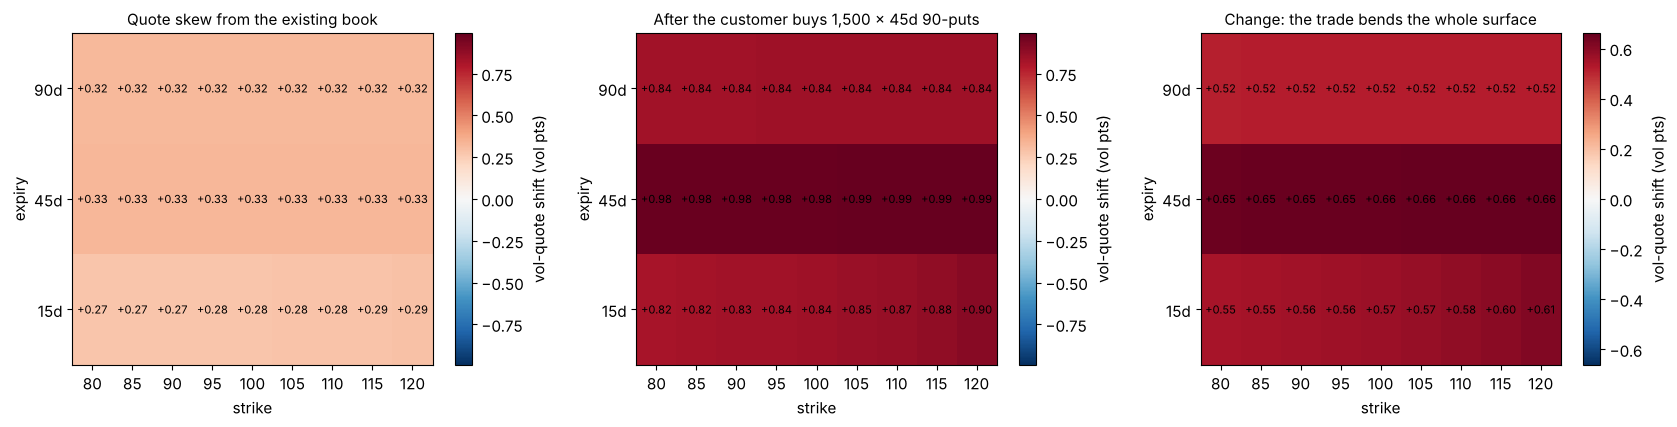

Exposures before (vega 15d, 45d, 90d, gamma$): [  -553.  -3812.  -3659. -43951.];  after: [   -553.  -17935.   -3659. -201120.]
Shorter vega + shorter gamma -> every quote marked up: most in the 45d bucket the customer hit, less in the correlated
neighbours, and with an extra lift on the short-dated wings where the gamma risk sits.
Gârleanu-Pedersen-Poteshman: this is the mechanism by which end-user demand shows up as the smile itself.


In [25]:
# --- Inventory skew: how the book moves the quotes, before and after one more big customer trade ---
# Risk factors: vega in each expiry bucket (daily vol moves of 1.5 pts, correlated 0.8 between neighbours, 0.6 across the curve)
# plus a gamma-dollar factor driven by a 1.25% daily spot move. The desk's penalty is quadratic in these exposures.
s_vol_day, s_ret_day = 0.015, 0.0125
vol_corr = np.array([[1.0, 0.8, 0.6], [0.8, 1.0, 0.8], [0.6, 0.8, 1.0]])
Lambda = np.zeros((4, 4))
Lambda[:3, :3] = s_vol_day**2 * vol_corr
Lambda[3, 3] = (s_ret_day**2 * np.sqrt(2))**2
gamma_ra = 2.0e-3

def exposures(pos_df):
    G = np.zeros(4)
    for kind in ("call", "put"):
        b = pos_df[pos_df.kind == kind]
        g = bs_greeks(S0, b.K.values, b["T"].values, r, q, b.sigma.values, kind)
        for i, T in enumerate(book_expiries):
            m = np.isclose(b["T"].values, T)
            G[i] += np.sum(b.pos.values[m] * g["vega"][m])
        G[3] += np.sum(b.pos.values * 0.5 * g["gamma"] * S0**2)
    return G

def quote_skew_grid(G):
    """Vol-quote shift (vol points) for every (strike, expiry): -gamma * g_i' Lambda G / vega_i. Same for calls and puts."""
    out = np.zeros((len(book_expiries), len(book_strikes)))
    for i, T in enumerate(book_expiries):
        g = bs_greeks(S0, book_strikes, T, r, q, surface_vol(book_strikes, T), "call")
        g_i = np.zeros((4, len(book_strikes)))
        g_i[i] = g["vega"]
        g_i[3] = 0.5 * g["gamma"] * S0**2
        out[i] = -gamma_ra * (g_i.T @ Lambda @ G) / g["vega"] * 100
    return out

G_before = exposures(book)
book_after = book.copy()
mask = (book_after.kind == "put") & (book_after.K == 90.0) & (np.isclose(book_after["T"], 45 * DAY))
book_after.loc[mask, "pos"] -= 1500                                       # a customer buys 1,500 more 45d 90-puts
G_after = exposures(book_after)
skew_before, skew_after = quote_skew_grid(G_before), quote_skew_grid(G_after)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
lim = max(np.abs(skew_before).max(), np.abs(skew_after).max())
for ax, Z, title in [(axes[0], skew_before, "Quote skew from the existing book"),
                     (axes[1], skew_after, "After the customer buys 1,500 x 45d 90-puts"),
                     (axes[2], skew_after - skew_before, "Change: the trade bends the whole surface")]:
    l = lim if ax is not axes[2] else np.abs(skew_after - skew_before).max()
    im = ax.imshow(Z, cmap="RdBu_r", norm=TwoSlopeNorm(0, -l, l), aspect="auto", origin="lower")
    ax.set_xticks(range(len(book_strikes))); ax.set_xticklabels([f"{int(k)}" for k in book_strikes])
    ax.set_yticks(range(len(book_expiries))); ax.set_yticklabels([f"{int(t/DAY)}d" for t in book_expiries])
    ax.set_xlabel("strike"); ax.set_ylabel("expiry"); ax.set_title(title, fontsize=11); ax.grid(False)
    for (i, j), val in np.ndenumerate(Z):
        ax.text(j, i, f"{val:+.2f}", ha="center", va="center", fontsize=8, color="k")
    fig.colorbar(im, ax=ax, label="vol-quote shift (vol pts)")
plt.tight_layout(); plt.show()
print(f"Exposures before (vega 15d, 45d, 90d, gamma$): {G_before.round(0)};  after: {G_after.round(0)}")
print("Shorter vega + shorter gamma -> every quote marked up: most in the 45d bucket the customer hit, less in the correlated")
print("neighbours, and with an extra lift on the short-dated wings where the gamma risk sits.")
print("Gârleanu-Pedersen-Poteshman: this is the mechanism by which end-user demand shows up as the smile itself.")
assert np.all(skew_after - skew_before > 0), "selling more vega to the customer must raise every quote"

## 10. Putting it together: a full options market-making simulation

Everything above, running at once on a synthetic single-name book for one trading week:

* **The world.** Spot follows Heston under $\mathbb P$ with occasional jumps (news); the
  "fair" surface is the $\mathbb Q$ variance-swap rate with a fixed sticky-moneyness skew,
  so theo moves with both spot and the variance state. 9 strikes x 2 expiries x calls and
  puts = 36 series.
* **The flow.** Poisson arrivals. A fraction $\alpha$ is *informed*: they see the surface one
  day ahead (a vol regime shift, a jump) and pick the option/side with the largest expected
  gain net of the half-spread. The rest are *uninformed*: random series, random side, and
  elastic — they walk away from a wide quote with probability $1 - e^{-k\,h_\sigma}$.
* **Two market makers on identical paths and identical arrivals.**
  *Naive*: flat 1-vol-point half-spread, no inventory skew, delta-hedge every 5 minutes.
  *Desk*: half-spread = margin + $\hat\alpha\times$ expected one-day **un-hedgeable** theo
  move of that series (vega and gamma; the delta part is hedged away, so charging for it only
  loses customers — the Glosten-Milgrom logic of Section 7 applied series by series),
  tick-aware (Section 3), inventory skew in Greek space (Section 9), delta hedged to a
  band (Section 5).
* **The P&L explain.** Total P&L is decomposed exactly into *spread capture* (fill vs. theo),
  *inventory theo P&L*, *hedge P&L* and *costs*, and the inventory theo P&L is further
  attributed to delta, gamma, theta and vega with a residual. Adverse selection is measured
  the Huang-Stoll way, but on the *delta-hedged* theo: the one-day move of the option's value
  net of its delta times the spot move, signed against the market maker. The un-hedged
  version would count the jump the market maker hedged before it happened.

In [26]:
def simulate_world(seed, n_days=5, steps_per_day=78, kappa=3.0, theta_P=0.04, theta_Q=0.05, xi=0.6, rho=-0.7,
                   jump_rate_per_day=0.4, jump_size=0.015, beta_skew=-0.6):
    """Spot/variance path plus the full theo and Greek matrices for every series at every step.
    Precomputing them is what lets informed traders 'see the future' and keeps the MM loop cheap."""
    rng = np.random.default_rng(seed)
    n = n_days * steps_per_day
    dt = DAY / steps_per_day
    strikes = np.arange(92.0, 109.0, 2.0)
    T0 = np.array([15 * DAY, 45 * DAY])
    K = np.tile(np.repeat(strikes, 2), len(T0))                       # (36,)  strike per series
    Texp = np.repeat(T0, 2 * len(strikes))                            # expiry per series
    is_call = np.tile(np.array([True, False]), len(strikes) * len(T0))
    S = np.empty(n + 1); v = np.empty(n + 1); S[0], v[0] = S0, theta_P
    jumps = rng.random(n) < jump_rate_per_day * dt / DAY
    for t in range(n):
        vp = max(v[t], 1e-8)
        Z1 = rng.standard_normal(); Z2 = rho * Z1 + np.sqrt(1 - rho**2) * rng.standard_normal()
        J = jump_size * rng.choice([-1, 1]) if jumps[t] else 0.0
        S[t + 1] = S[t] * np.exp(-0.5 * vp * dt + np.sqrt(vp * dt) * Z1 + J)
        v[t + 1] = v[t] + kappa * (theta_P - vp) * dt + xi * np.sqrt(vp * dt) * Z2
    v = np.maximum(v, 1e-8)
    # fair surface and Greeks for all series at all steps
    tau = Texp[None, :] - np.arange(n + 1)[:, None] * dt                # (n+1, 36)
    base = np.sqrt(theta_Q + (v[:, None] - theta_Q) * (1 - np.exp(-kappa * tau)) / (kappa * tau))
    sig = np.clip(base * (1 + beta_skew * np.log(K[None, :] / S[:, None])), 0.05, 2.0)
    G = {k: np.empty((n + 1, len(K))) for k in ("price", "delta", "gamma", "vega", "theta")}
    for kind, m in (("call", is_call), ("put", ~is_call)):
        g = bs_greeks(S[:, None], K[None, m], tau[:, m], r, q, sig[:, m], kind)
        for k in G:
            G[k][:, m] = g[k]
    return dict(S=S, v=v, sig=sig, K=K, T=Texp, is_call=is_call, dt=dt, n=n, jumps=jumps, steps_per_day=steps_per_day, **G)

def run_market_maker(world, seed, desk, alpha=0.2, lam_per_step=3.0, k_el=60.0, margin_vol=0.005, gamma_inv=0.15,
                     hedge_band=2.0, stock_cost=0.01, horizon_steps=None, jump_rate_per_day=0.4, jump_size=0.015):
    """One market maker over one world. desk=False: naive flat spread; desk=True: everything from Sections 3-9."""
    rng = np.random.default_rng(seed)
    n, dt, nS = world["n"], world["dt"], len(world["K"])
    H = horizon_steps or world["steps_per_day"]
    S, price, delta, gamma, vega, theta, sig = (world[k] for k in ("S", "price", "delta", "gamma", "vega", "theta", "sig"))
    s_vol_day = 0.6 * np.sqrt(0.04) / (2 * np.sqrt(0.04)) * np.sqrt(DAY) * 0.8     # ~ daily std of fair vol, in vol units
    Lambda = np.diag([s_vol_day**2, (0.0125**2 * np.sqrt(2))**2])
    pos = np.zeros(nS); shares = 0.0; cash = 0.0
    comp = dict(spread=0.0, inv_theo=0.0, hedge=0.0, cost=0.0, adverse=0.0, n_fills=0, n_informed_fills=0, eff_spread=0.0)
    attr = dict(delta=0.0, gamma=0.0, theta=0.0, vega=0.0, resid=0.0)
    hist = dict(pnl=np.zeros(n + 1), vega=np.zeros(n + 1), spread=np.zeros(n + 1), adverse=np.zeros(n + 1),
                hedge_plus_delta=np.zeros(n + 1), gamma=np.zeros(n + 1), theta=np.zeros(n + 1), vega_pnl=np.zeros(n + 1),
                cost=np.zeros(n + 1), bid_vol=np.zeros(n + 1), ask_vol=np.zeros(n + 1), resid=np.zeros(n + 1))
    watch = 2 * 4 + 0 + 2 * len(np.arange(92.0, 109.0, 2.0))           # the 45d 100-call, for the quote plot
    for t in range(n):
        th, dl, gm, vg = price[t], delta[t], gamma[t], vega[t]
        tick = np.where(th < 3.0, 0.01, 0.05)
        if desk:
            # what an informed fill can cost AFTER the delta hedge: the vega move and the gamma on a day's variance (jumps included)
            day_var = world["v"][t] * DAY + jump_rate_per_day * jump_size**2
            exp_unhedgeable = vg * s_vol_day * np.sqrt(2 / np.pi) + 0.5 * gm * S[t]**2 * day_var
            h_dollar = np.maximum(margin_vol * vg, tick / 2) + alpha * exp_unhedgeable
            G = np.array([np.sum(pos * vg), np.sum(pos * 0.5 * gm * S[t]**2)])
            g_i = np.vstack([vg, 0.5 * gm * S[t]**2])
            skew_vol = np.clip(-gamma_inv * (g_i.T @ Lambda @ G) / vg, -0.03, 0.03)
        else:
            h_dollar = np.maximum(0.01 * vg, tick / 2)
            skew_vol = np.zeros(nS)
        h_vol = h_dollar / vg
        bid = th + skew_vol * vg - h_dollar
        ask = th + skew_vol * vg + h_dollar
        hist["bid_vol"][t], hist["ask_vol"][t] = sig[t, watch] + skew_vol[watch] - h_vol[watch], sig[t, watch] + skew_vol[watch] + h_vol[watch]
        t_h = min(t + H, n)
        for _ in range(rng.poisson(lam_per_step)):
            if rng.random() < alpha:                                    # informed: sees theo one day ahead
                fut = price[t_h]
                gain_buy, gain_sell = fut - ask, bid - fut
                i_b, i_s = np.argmax(gain_buy), np.argmax(gain_sell)
                if max(gain_buy[i_b], gain_sell[i_s]) <= 0:
                    continue
                if gain_buy[i_b] >= gain_sell[i_s]:
                    i, mm_side, px = i_b, -1, ask[i_b]                  # customer buys, MM sells at the ask
                else:
                    i, mm_side, px = i_s, +1, bid[i_s]
                comp["n_informed_fills"] += 1
            else:                                                       # uninformed: random series/side, walks from wide quotes
                i = rng.integers(nS)
                if rng.random() > np.exp(-k_el * h_vol[i]):
                    continue
                mm_side = 1 if rng.random() < 0.5 else -1
                px = bid[i] if mm_side == 1 else ask[i]
            pos[i] += mm_side; cash -= mm_side * px
            comp["spread"] += mm_side * (th[i] - px)
            comp["eff_spread"] += abs(th[i] - px)
            comp["adverse"] += mm_side * ((price[t_h, i] - th[i]) - dl[i] * (S[t_h] - S[t]))   # delta-hedged theo move
            comp["n_fills"] += 1
        # delta hedge
        port_delta = np.sum(pos * dl) + shares
        if (not desk) or abs(port_delta) > hedge_band:
            trade = -port_delta
            cash -= trade * S[t] + stock_cost * abs(trade)
            comp["cost"] += stock_cost * abs(trade); shares += trade
        # the world moves
        dS = S[t + 1] - S[t]
        inv_move = np.sum(pos * (price[t + 1] - th))
        comp["inv_theo"] += inv_move; comp["hedge"] += shares * dS
        a_delta = np.sum(pos * dl) * dS; a_gamma = np.sum(pos * 0.5 * gm * dS**2)
        a_theta = np.sum(pos * theta[t]) * dt; a_vega = np.sum(pos * vg * (sig[t + 1] - sig[t]))
        attr["delta"] += a_delta; attr["gamma"] += a_gamma; attr["theta"] += a_theta; attr["vega"] += a_vega
        attr["resid"] += inv_move - a_delta - a_gamma - a_theta - a_vega
        total = cash + np.sum(pos * price[t + 1]) + shares * S[t + 1]
        hist["pnl"][t + 1] = total; hist["vega"][t + 1] = np.sum(pos * vega[t + 1])
        hist["spread"][t + 1] = comp["spread"]; hist["adverse"][t + 1] = comp["adverse"]; hist["cost"][t + 1] = -comp["cost"]
        hist["hedge_plus_delta"][t + 1] = comp["hedge"] + attr["delta"]; hist["gamma"][t + 1] = attr["gamma"]
        hist["theta"][t + 1] = attr["theta"]; hist["vega_pnl"][t + 1] = attr["vega"]; hist["resid"][t + 1] = attr["resid"]
    total = cash + np.sum(pos * price[n]) + shares * S[n]
    recon = comp["spread"] + comp["inv_theo"] + comp["hedge"] - comp["cost"]
    assert abs(total - recon) < 1e-6, (total, recon)
    recon2 = comp["spread"] + sum(attr.values()) + comp["hedge"] - comp["cost"]
    assert abs(total - recon2) < 1e-6
    return dict(total=total, comp=comp, attr=attr, hist=hist, pos=pos, shares=shares)

world = simulate_world(seed=100)
naive = run_market_maker(world, seed=200, desk=False)
desk = run_market_maker(world, seed=200, desk=True)
for name, res in (("Naive", naive), ("Desk", desk)):
    c = res["comp"]
    print(f"{name:6s} total P&L {res['total']:+8.2f} | spread capture {c['spread']:+8.2f} | adverse selection {c['adverse']:+8.2f} "
          f"| inventory theo {c['inv_theo']:+8.2f} | hedge {c['hedge']:+8.2f} | costs {-c['cost']:+7.2f} | fills {c['n_fills']} ({c['n_informed_fills']} informed)")
print("P&L reconciles exactly to its components for both market makers (asserted inside the loop).")

Naive  total P&L   +49.13 | spread capture   +47.84 | adverse selection    -0.72 | inventory theo  -284.54 | hedge  +288.86 | costs   -3.04 | fills 668 (217 informed)
Desk   total P&L   +39.04 | spread capture   +47.87 | adverse selection    -8.05 | inventory theo  -359.32 | hedge  +352.78 | costs   -2.29 | fills 711 (234 informed)
P&L reconciles exactly to its components for both market makers (asserted inside the loop).


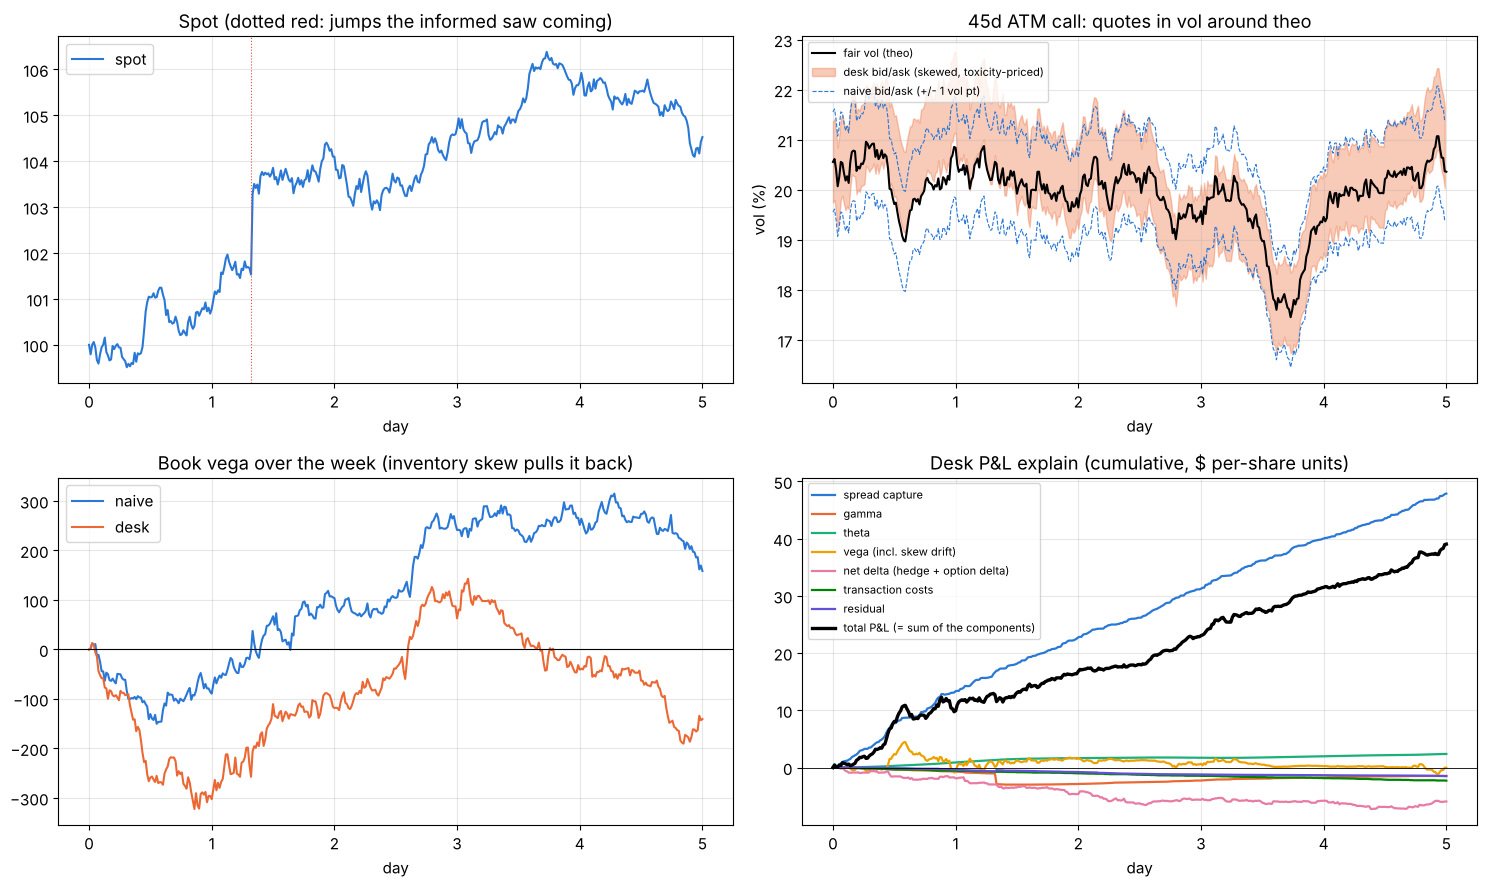

Desk attribution: {'delta': -358.71, 'gamma': -1.45, 'theta': 2.38, 'vega': -0.03, 'resid': -1.51} | spread 47.87 | hedge 352.78 | cost -2.29
Residual of the Greek attribution is 3.9% of total P&L: the Taylor expansion of Section 9 holds at 5-minute granularity.


In [27]:
# --- One week on the desk: the world, the quotes around theo, inventory, and the P&L explain ---
tgrid = np.arange(world["n"] + 1) / world["steps_per_day"]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes[0, 0].plot(tgrid, world["S"], lw=1.5, color=PALETTE[0], label="spot")
for j in np.where(world["jumps"])[0]:
    axes[0, 0].axvline(tgrid[j], color=PALETTE[7], lw=0.8, ls=":")
axes[0, 0].set_title("Spot (dotted red: jumps the informed saw coming)"); axes[0, 0].set_xlabel("day"); axes[0, 0].legend(loc="upper left")
ax2 = axes[0, 1]
watch = 2 * 4 + 2 * len(np.arange(92.0, 109.0, 2.0))
ax2.plot(tgrid, world["sig"][:, watch] * 100, lw=1.5, color="k", label="fair vol (theo)")
ax2.fill_between(tgrid[:-1], desk["hist"]["bid_vol"][:-1] * 100, desk["hist"]["ask_vol"][:-1] * 100, alpha=0.35, color=PALETTE[1], label="desk bid/ask (skewed, toxicity-priced)")
ax2.plot(tgrid[:-1], naive["hist"]["bid_vol"][:-1] * 100, lw=0.8, color=PALETTE[0], ls="--", label="naive bid/ask (+/- 1 vol pt)")
ax2.plot(tgrid[:-1], naive["hist"]["ask_vol"][:-1] * 100, lw=0.8, color=PALETTE[0], ls="--")
ax2.set_title("45d ATM call: quotes in vol around theo"); ax2.set_xlabel("day"); ax2.set_ylabel("vol (%)"); ax2.legend(fontsize=8, loc="upper left")
axes[1, 0].plot(tgrid, naive["hist"]["vega"], lw=1.5, label="naive")
axes[1, 0].plot(tgrid, desk["hist"]["vega"], lw=1.5, label="desk")
axes[1, 0].axhline(0, color="k", lw=0.8); axes[1, 0].set_title("Book vega over the week (inventory skew pulls it back)"); axes[1, 0].set_xlabel("day"); axes[1, 0].legend()
h = desk["hist"]
parts = [("spread capture", h["spread"]), ("gamma", h["gamma"]), ("theta", h["theta"]), ("vega (incl. skew drift)", h["vega_pnl"]),
         ("net delta (hedge + option delta)", h["hedge_plus_delta"]), ("transaction costs", h["cost"]), ("residual", h["resid"])]
for (lab, series), col in zip(parts, PALETTE):
    axes[1, 1].plot(tgrid, series, color=col, lw=1.6, label=lab)
axes[1, 1].plot(tgrid, h["pnl"], color="k", lw=2.4, label="total P&L (= sum of the components)")
axes[1, 1].axhline(0, color="k", lw=0.6)
axes[1, 1].set_title("Desk P&L explain (cumulative, $ per-share units)"); axes[1, 1].set_xlabel("day"); axes[1, 1].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()
a = desk["attr"]; c = desk["comp"]
print("Desk attribution:", {k: round(float(v), 2) for k, v in a.items()}, "| spread", round(c["spread"], 2), "| hedge", round(c["hedge"], 2), "| cost", round(-c["cost"], 2))
print(f"Residual of the Greek attribution is {abs(a['resid'])/max(abs(desk['total']),1e-9):.1%} of total P&L: the Taylor expansion of Section 9 holds at 5-minute granularity.")

mm                       desk    naive
mean_pnl               40.595   43.047
std_pnl                 8.857   12.484
worst                  13.312   -5.238
fills                 741.067  723.067
informed_share          0.313    0.324
eff_half_spread         0.075    0.075
realized_half_spread    0.057    0.061
adverse_selection      -8.683   -9.896
costs                  -2.285   -3.411
max_abs_vega          317.925  449.818
sharpe_weekly           4.583    3.448


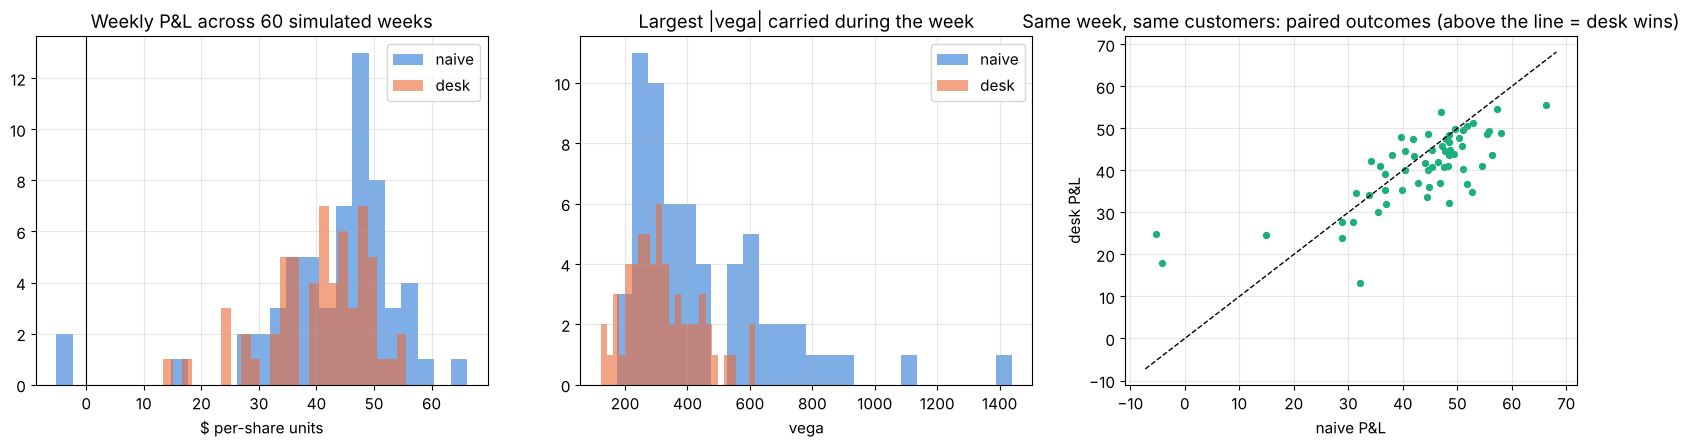


Effective half-spread earned per fill: naive 0.0745, desk 0.0750.
After adverse selection (realized half-spread): naive 0.0609, desk 0.0574.
Share of fills that were informed: naive 32%, desk 31%.
Desk wins 28% of paired weeks; mean P&L 40.60 vs 43.05; P&L std 8.86 vs 12.48; worst week 13.31 vs -5.24.


In [28]:
# --- Many weeks: distribution of outcomes, naive vs desk, identical worlds and arrivals ---
n_sims = 60
rows = []
for s in range(n_sims):
    w_ = simulate_world(seed=1000 + s)
    for name, is_desk in (("naive", False), ("desk", True)):
        res = run_market_maker(w_, seed=5000 + s, desk=is_desk)
        c = res["comp"]
        rows.append(dict(sim=s, mm=name, total=res["total"], spread=c["spread"], adverse=c["adverse"], cost=-c["cost"],
                         fills=c["n_fills"], informed=c["n_informed_fills"], max_abs_vega=np.abs(res["hist"]["vega"]).max(),
                         eff_half_spread=c["eff_spread"] / max(c["n_fills"], 1),
                         realized_half_spread=(c["spread"] + c["adverse"]) / max(c["n_fills"], 1)))
df = pd.DataFrame(rows)
summary = df.groupby("mm").agg(mean_pnl=("total", "mean"), std_pnl=("total", "std"), worst=("total", "min"),
                               fills=("fills", "mean"), informed_share=("informed", lambda x: x.sum()),
                               eff_half_spread=("eff_half_spread", "mean"), realized_half_spread=("realized_half_spread", "mean"),
                               adverse_selection=("adverse", "mean"), costs=("cost", "mean"), max_abs_vega=("max_abs_vega", "mean"))
summary["informed_share"] = summary["informed_share"] / df.groupby("mm")["fills"].sum()
summary["sharpe_weekly"] = summary["mean_pnl"] / summary["std_pnl"]
print(summary.T.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for name, col in (("naive", PALETTE[0]), ("desk", PALETTE[1])):
    d = df[df.mm == name]
    axes[0].hist(d.total, bins=25, alpha=0.6, color=col, label=name)
    axes[1].hist(d.max_abs_vega, bins=25, alpha=0.6, color=col, label=name)
axes[0].axvline(0, color="k", lw=0.8); axes[0].set_title(f"Weekly P&L across {n_sims} simulated weeks"); axes[0].set_xlabel("$ per-share units"); axes[0].legend()
axes[1].set_title("Largest |vega| carried during the week"); axes[1].set_xlabel("vega"); axes[1].legend()
pv = df.pivot(index="sim", columns="mm", values="total")
axes[2].scatter(pv["naive"], pv["desk"], s=18, color=PALETTE[2])
lim = [min(pv.min()) - 2, max(pv.max()) + 2]; axes[2].plot(lim, lim, "k--", lw=1)
axes[2].set_xlabel("naive P&L"); axes[2].set_ylabel("desk P&L"); axes[2].set_title("Same week, same customers: paired outcomes (above the line = desk wins)")
plt.tight_layout(); plt.show()
desk_s, naive_s = summary.loc["desk"], summary.loc["naive"]
print(f"\nEffective half-spread earned per fill: naive {naive_s.eff_half_spread:.4f}, desk {desk_s.eff_half_spread:.4f}.")
print(f"After adverse selection (realized half-spread): naive {naive_s.realized_half_spread:.4f}, desk {desk_s.realized_half_spread:.4f}.")
print(f"Share of fills that were informed: naive {naive_s.informed_share:.0%}, desk {desk_s.informed_share:.0%}.")
print(f"Desk wins {np.mean(pv['desk'] > pv['naive']):.0%} of paired weeks; mean P&L {desk_s.mean_pnl:.2f} vs {naive_s.mean_pnl:.2f}; "
      f"P&L std {desk_s.std_pnl:.2f} vs {naive_s.std_pnl:.2f}; worst week {desk_s.worst:.2f} vs {naive_s.worst:.2f}.")

### Reading the result

Across the simulated weeks the desk earns a little less on average than the naive quoter and
has a markedly tighter distribution: lower dispersion, a far better worst week, and a higher
P&L-to-risk ratio. The effective half-spread per fill is essentially the same — the desk's
structured spread rule and the naive flat vol spread land in the same place *on average*, but
distribute it differently across series — while the inventory skew cuts the largest vega the
book carries by roughly a third, and the hedge band cuts transaction costs. Note what did
*not* happen: adverse selection is small for both, because the informed flow in this world is
mostly directional and the market maker hedges delta before the move lands. The un-hedgeable
part (vega, gamma through a jump) is what remains, and that is exactly what the desk's
spread rule charges for. That is the shape of the real business: the spread is roughly a
given, the edge is in what you keep and how much risk you carry while keeping it.

## 11. Method comparison and references

What the notebook showed, section by section, and where each piece breaks:

In [29]:
comparison = pd.DataFrame([
    ["Black-Scholes Greeks as inventory coordinates", "Closed form, FD-verified", "Quoting convention and risk units on every desk", "A convention, not a model: real surface dynamics live outside it (Section 6)"],
    ["Vega-based vol/price spread conversion", "First-order Taylor", "Setting the quote width; tick-constraint diagnosis in the wings", "Second order (volga) matters for wide vol spreads and far wings"],
    ["Pick-off loss: half-normal closed form vs jump model", "Analytic + discrete mixture", "Latency budgeting; spread vs speed tradeoff", "Jump-size distribution and race model are stylised; real microstructure is queue-position dependent"],
    ["Fundamental hedging P&L identity", "Pathwise integral, checked on simulated paths", "Understanding what a hedged book earns; vol-arb P&L forecasting", "Exact only for continuous hedging; discrete error ~ 1/sqrt(N)"],
    ["Leland transaction-cost volatility", "Asymptotic adjustment", "Expected hedging cost at a given frequency", "First-order in k/(sigma sqrt(dt)); breaks when costs are large relative to the step"],
    ["Whalley-Wilmott no-trade band", "Asymptotic utility-optimal band", "Day-to-day hedge discipline", "Exponential utility, small-cost asymptotics; ignores gap risk"],
    ["Raw SVI + Durrleman/calendar checks", "5-param fit per slice, analytic derivatives", "The theo surface every quote hangs off", "Raw SVI is not arbitrage-free by construction; needs the checks (or the Gatheral-Jacquier SSVI restrictions)"],
    ["Sticky-strike vs sticky-delta hedge ratio", "Chain rule through the smile", "Choosing the hedge delta for skewed names", "Reality is a mixture (Hull-White minimum-variance delta); regime shifts"],
    ["Glosten-Milgrom sequential trade", "Bayesian updating, closed-form spread", "Flow segmentation and wholesaling economics", "Binary value, unit trades, no inventory; Kyle's model for the strategic version"],
    ["Dispersion via variance swaps", "Exact quadratic identity", "Index vs single-name vol book; correlation risk premium", "Single-correlation assumption; real baskets have factor structure and idiosyncratic jumps"],
    ["Forward/borrow/box extraction", "Put-call parity algebra", "Financing book; diagnosing a wrong forward", "Early exercise (American single-stock options) breaks parity; dividends are discrete"],
    ["Additive event variance", "Variance additivity", "Earnings term structure and expected move", "Jump distribution is fat-tailed and drifts; historical sample is small"],
    ["Expiry-day gamma / hedging error", "Simulation, 1/sqrt(N) law", "0DTE and pin-risk sizing", "Continuous-price model; real pin risk is about discrete assignment"],
    ["Variance risk premium (Heston P vs Q)", "Simulation with validated IV proxy", "Why the book is structurally short vol and what that costs", "Single-factor vol; premium size is an input, not an output"],
    ["Spot/vol grid and Taylor residual", "Full repricing vs second-order Greeks", "The daily risk report", "Grid is static: no path dependence, no liquidity in the scenario"],
    ["Greek-space inventory skew", "Quadratic risk penalty", "Reservation prices; demand-based skew", "Diagonal factor covariance; the real version uses the full P&L covariance across the book"],
    ["Full MM simulation with P&L explain", "Agent-based, exactly reconciled", "Seeing the pieces interact", "Stylised flow model; informed traders here are omniscient about one day ahead"],
], columns=["Method", "Approach", "Used for", "Main limitation"])
pd.set_option("display.max_colwidth", 70)
comparison

,Method,Approach,Used for,Main limitation
0,Black-Scholes Greeks as inventory coordinates,"Closed form, FD-verified",Quoting convention and risk units on every desk,"A convention, not a model: real surface dynamics live outside it (..."
1,Vega-based vol/price spread conversion,First-order Taylor,Setting the quote width; tick-constraint diagnosis in the wings,Second order (volga) matters for wide vol spreads and far wings
2,Pick-off loss: half-normal closed form vs jump model,Analytic + discrete mixture,Latency budgeting; spread vs speed tradeoff,Jump-size distribution and race model are stylised; real microstru...
3,Fundamental hedging P&L identity,"Pathwise integral, checked on simulated paths",Understanding what a hedged book earns; vol-arb P&L forecasting,Exact only for continuous hedging; discrete error ~ 1/sqrt(N)
4,Leland transaction-cost volatility,Asymptotic adjustment,Expected hedging cost at a given frequency,First-order in k/(sigma sqrt(dt)); breaks when costs are large rel...
5,Whalley-Wilmott no-trade band,Asymptotic utility-optimal band,Day-to-day hedge discipline,"Exponential utility, small-cost asymptotics; ignores gap risk"
6,Raw SVI + Durrleman/calendar checks,"5-param fit per slice, analytic derivatives",The theo surface every quote hangs off,Raw SVI is not arbitrage-free by construction; needs the checks (o...
7,Sticky-strike vs sticky-delta hedge ratio,Chain rule through the smile,Choosing the hedge delta for skewed names,Reality is a mixture (Hull-White minimum-variance delta); regime s...
8,Glosten-Milgrom sequential trade,"Bayesian updating, closed-form spread",Flow segmentation and wholesaling economics,"Binary value, unit trades, no inventory; Kyle's model for the stra..."
9,Dispersion via variance swaps,Exact quadratic identity,Index vs single-name vol book; correlation risk premium,Single-correlation assumption; real baskets have factor structure ...


### What this notebook cannot show you

Brutal honesty section. The mathematics above is what the large firms *also* use; it is not
what makes them large. The parts that are not reproducible here:

* **Flow.** A wholesaler sees the retail order before it reaches an exchange. A large exchange
  market maker sees its own fills across every venue in real time. Both calibrate $\alpha$ and
  the toxicity model from millions of fills a day. The sim above gives $\alpha$ to the desk
  for free; in reality estimating it is the business.
* **Speed and scale.** Mass-quoting tens of thousands of series across 16-plus exchanges within
  microseconds of an underlying tick is an engineering achievement, not a formula. Section 4
  shows why it is worth paying for; it cannot show how.
* **Calibration stability.** The SVI fit here is on clean synthetic data. Real surfaces have
  stale quotes, crossed markets, pre-open noise, dividend uncertainty and early exercise; most
  of a surface team's time goes to *not* re-fitting on garbage.
* **The real risk framework.** Greek ladders and the spot/vol grid are the start. Firms stress
  the full book against historical scenarios (1987, 2008, Feb 2018, Mar 2020, Aug 2024), run
  liquidity-adjusted VaR, and set limits per name, per expiry and per desk. Section 9 is the
  skeleton of that.
* **Everything below the Greeks.** Clearing, margin (OCC's risk-based margining is itself a
  grid), financing of the hedge book, and exchange fee schedules decide which quotes are
  profitable at the margin — and those vary venue by venue.

### References

**Market making and microstructure**
1. Glosten, L. R. & Milgrom, P. R. (1985). *Bid, Ask and Transaction Prices in a Specialist Market with Heterogeneously Informed Traders*. Journal of Financial Economics, 14(1), 71-100.
2. Kyle, A. S. (1985). *Continuous Auctions and Insider Trading*. Econometrica, 53(6), 1315-1335.
3. Ho, T. & Stoll, H. R. (1981). *Optimal Dealer Pricing under Transactions and Return Uncertainty*. Journal of Financial Economics, 9(1), 47-73.
4. Copeland, T. E. & Galai, D. (1983). *Information Effects on the Bid-Ask Spread*. Journal of Finance, 38(5), 1457-1469.
5. Avellaneda, M. & Stoikov, S. (2008). *High-Frequency Trading in a Limit Order Book*. Quantitative Finance, 8(3), 217-224.
6. Stoikov, S. & Sağlam, M. (2009). *Option Market Making under Inventory Risk*. Review of Derivatives Research, 12(1), 55-79.
7. Baldacci, B., Bergault, P. & Guéant, O. (2021). *Algorithmic Market Making for Options*. Quantitative Finance, 21(1), 85-97.
8. Guéant, O. (2016). *The Financial Mathematics of Market Liquidity*. Chapman & Hall/CRC.
9. Budish, E., Cramton, P. & Shim, J. (2015). *The High-Frequency Trading Arms Race: Frequent Batch Auctions as a Market Design Response*. Quarterly Journal of Economics, 130(4), 1547-1621.
10. Huang, R. D. & Stoll, H. R. (1996). *Dealer versus Auction Markets: A Paired Comparison of Execution Costs on NASDAQ and the NYSE*. Journal of Financial Economics, 41(3), 313-357.
11. Easley, D., O'Hara, M. & Srinivas, P. S. (1998). *Option Volume and Stock Prices: Evidence on Where Informed Traders Trade*. Journal of Finance, 53(2), 431-465.
12. Muravyev, D. (2016). *Order Flow and Expected Option Returns*. Journal of Finance, 71(2), 673-708.
13. Gârleanu, N., Pedersen, L. H. & Poteshman, A. M. (2009). *Demand-Based Option Pricing*. Review of Financial Studies, 22(10), 4259-4299.
14. Bouchaud, J.-P., Bonart, J., Donier, J. & Gould, M. (2018). *Trades, Quotes and Prices: Financial Markets Under the Microscope*. Cambridge University Press.

**Hedging**
15. Black, F. & Scholes, M. (1973). *The Pricing of Options and Corporate Liabilities*. Journal of Political Economy, 81(3), 637-654.
16. Merton, R. C. (1973). *Theory of Rational Option Pricing*. Bell Journal of Economics and Management Science, 4(1), 141-183.
17. El Karoui, N., Jeanblanc-Picqué, M. & Shreve, S. E. (1998). *Robustness of the Black and Scholes Formula*. Mathematical Finance, 8(2), 93-126.
18. Carr, P. & Madan, D. (2001). *Towards a Theory of Volatility Trading*. In: Jouini, Cvitanić & Musiela (eds.), *Option Pricing, Interest Rates and Risk Management*, Cambridge University Press.
19. Boyle, P. P. & Emanuel, D. (1980). *Discretely Adjusted Option Hedges*. Journal of Financial Economics, 8(3), 259-282.
20. Derman, E. & Kamal, M. (1999). *When You Cannot Hedge Continuously: The Corrections of Black-Scholes*. Goldman Sachs Quantitative Strategies Research Notes.
21. Leland, H. E. (1985). *Option Pricing and Replication with Transactions Costs*. Journal of Finance, 40(5), 1283-1301.
22. Whalley, A. E. & Wilmott, P. (1997). *An Asymptotic Analysis of an Optimal Hedging Model for Option Pricing with Transaction Costs*. Mathematical Finance, 7(3), 307-324.
23. Zakamouline, V. (2006). *European Option Pricing and Hedging with Both Fixed and Proportional Transaction Costs*. Journal of Economic Dynamics and Control, 30(1), 1-25.
24. Taleb, N. N. (1997). *Dynamic Hedging: Managing Vanilla and Exotic Options*. Wiley.

**The surface**
25. Heston, S. L. (1993). *A Closed-Form Solution for Options with Stochastic Volatility with Applications to Bond and Currency Options*. Review of Financial Studies, 6(2), 327-343.
26. Gatheral, J. (2004). *A Parsimonious Arbitrage-Free Implied Volatility Parameterization with Application to the Valuation of Volatility Derivatives*. Global Derivatives & Risk Management, Madrid.
27. Gatheral, J. & Jacquier, A. (2014). *Arbitrage-Free SVI Volatility Surfaces*. Quantitative Finance, 14(1), 59-71.
28. Durrleman, V. (2003). *A Note on Initial Volatility Surface*. Working paper, Stanford University.
29. Derman, E. (1999). *Regimes of Volatility*. Risk, April 1999, 55-59.
30. Hull, J. & White, A. (2017). *Optimal Delta Hedging for Options*. Journal of Banking & Finance, 82, 180-190.

**Strategies**
31. Driessen, J., Maenhout, P. J. & Vilkov, G. (2009). *The Price of Correlation Risk: Evidence from Equity Options*. Journal of Finance, 64(3), 1377-1406.
32. Bossu, S. (2005). *Arbitrage Pricing of Equity Correlation Swaps*. JPMorgan Equity Derivatives working paper.
33. van Binsbergen, J. H., Diamond, W. F. & Grotteria, M. (2022). *Risk-Free Interest Rates*. Journal of Financial Economics, 143(1), 1-29.
34. Ofek, E., Richardson, M. & Whitelaw, R. F. (2004). *Limited Arbitrage and Short Sales Restrictions: Evidence from the Options Markets*. Journal of Financial Economics, 74(2), 305-342.
35. Dubinsky, A., Johannes, M., Kaeck, A. & Seeger, N. J. (2019). *Option Pricing of Earnings Announcement Risks*. Review of Financial Studies, 32(2), 646-687.
36. Patell, J. M. & Wolfson, M. A. (1981). *The Ex Ante and Ex Post Price Effects of Quarterly Earnings Announcements Reflected in Option and Stock Prices*. Journal of Accounting Research, 19(2), 434-458.
37. Brenner, M. & Subrahmanyam, M. G. (1988). *A Simple Formula to Compute the Implied Standard Deviation*. Financial Analysts Journal, 44(5), 80-83.
38. Bakshi, G. & Kapadia, N. (2003). *Delta-Hedged Gains and the Negative Market Volatility Risk Premium*. Review of Financial Studies, 16(2), 527-566.
39. Carr, P. & Wu, L. (2009). *Variance Risk Premiums*. Review of Financial Studies, 22(3), 1311-1341.
40. Bollerslev, T., Tauchen, G. & Zhou, H. (2009). *Expected Stock Returns and Variance Risk Premia*. Review of Financial Studies, 22(11), 4463-4492.

**Practitioner texts and public market-structure sources**
41. Natenberg, S. (2015). *Option Volatility and Pricing*, 2nd ed. McGraw-Hill.
42. Sinclair, E. (2013). *Volatility Trading*, 2nd ed. Wiley.
43. SEC Rule 606 order-routing disclosures of US retail brokers (for the identity of the options wholesalers); Cboe Global Markets public statistics and commentary on SPX 0DTE volume; exchange DMM/LMM appointment lists.